# Instituto Superior de Engenharia do Porto (ISEP)
## Departamento de Engenharia Electrotécnica (DEE)
### Unidade Curricular: Sinais e Sistemas (SINSI) - Ano Letivo 2026/2027

---
# Resolução Detalhada da Folha Prática TP06a
## Série de Fourier em Tempo Contínuo (SFTC): Decomposição Harmónica, Formas Exponencial e Trigonométrica, Propriedades, Espectros de Linha e Fenómeno de Gibbs

**Docente:** Luís Pinto-Coelho

---

### Objetivos Pedagógicos e Competências a Desenvolver:
1. **Compreender a Série de Fourier em Tempo Contínuo (SFTC)** como a representação exata de qualquer sinal periódico de potência finita através de uma combinação linear de funções ortogonais da base de exponenciais complexas ou sinusóides harmónicas.
2. **Dominar a conversão bidirecional entre as três formas canónicas de representação**:
   * Forma Exponencial Complexa (bilateral: coeficientes $a_k$ ou $c_k$);
   * Forma Trigonométrica Retangular (unilateral: coeficientes $a_0, A_k, B_k$);
   * Forma Trigonométrica Compacta ou Polar (unilateral: amplitude $C_k$ e fase $\theta_k$).
3. **Explorar e aplicar as propriedades fundamentais da Série de Fourier** (linearidade, translação temporal, mudança de escala, inversão temporal e derivação) para determinar coeficientes sem necessidade de cálculo integral direto.
4. **Relacionar simetrias temporais com propriedades espectrais** (sinais reais, paridade par/ímpar e simetria de meia-onda), simplificando drasticamente o cálculo analítico e prevendo a anulação sistemática de coeficientes.
5. **Calcular a distribuição espectral de potência via Teorema de Parseval**, avaliando a conservação de energia e a Distorção Harmónica Total (THD) em contextos de Engenharia Electrotécnica (redes elétricas, filtros e eletrónica de potência).
6. **Analisar a convergência e o Fenómeno de Gibbs** em descontinuidades pontuais, articulando os resultados analíticos com o simulador interativo baseado na onda quadrada (`square_wave_fourier_lab.ipynb`).


## 1. Enquadramento Teórico Formal

---

### 1.1. Periodicidade e a Base de Funções Ortogonais

Um sinal em tempo contínuo $x(t)$ diz-se **periódico** se existir uma constante positiva $T_0 > 0$ tal que:
$$x(t) = x(t + T_0), \quad \forall t \in \mathbb{R}$$
O menor valor estritamente positivo de $T_0$ que satisfaz esta condição é denominado **período fundamental**. A **frequência angular fundamental** $\omega_0$ (expressa em $\text{rad/s}$) e a **frequência fundamental** $f_0$ (em $\text{Hz}$) são dadas por:
$$\omega_0 = \frac{2\pi}{T_0} = 2\pi f_0$$

A teoria da Série de Fourier estabelece que qualquer sinal periódico que cumpra as condições de integrabilidade pode ser expresso como uma expansão sobre o conjunto de funções exponenciais harmónicas:
$$\phi_k(t) = e^{j k \omega_0 t}, \quad k \in \mathbb{Z}$$

Esta família de funções goza da propriedade de **ortogonalidade** no intervalo de um período qualquer $[t_0, t_0 + T_0]$:
$$\frac{1}{T_0} \int_{t_0}^{t_0 + T_0} e^{j k \omega_0 t} e^{-j m \omega_0 t} \, dt = \frac{1}{T_0} \int_{T_0} e^{j(k - m)\omega_0 t} \, dt = \delta_{k,m} = \begin{cases} 1, & k = m \\ 0, & k \neq m \end{cases}$$
onde $\delta_{k,m}$ representa o delta de Kronecker. É precisamente esta ortogonalidade que permite isolar e calcular cada coeficiente harmónico individualmente por projeção integral.

---

### 1.2. As Três Formas da Série de Fourier e Relações de Conversão

Na literatura e na prática de Engenharia Electrotécnica coexistem três formas de representação da Série de Fourier, cada uma adaptada a determinados objetivos analíticos:

#### 1. Forma Exponencial Complexa (Bilateral)
A representação matemática mais elegante e compacta:
$$\boxed{x(t) = \sum_{k=-\infty}^{+\infty} a_k \, e^{j k \omega_0 t}} \quad \text{(Equação de Síntese)}$$
$$\boxed{a_k = \frac{1}{T_0} \int_{T_0} x(t) \, e^{-j k \omega_0 t} \, dt} \quad \text{(Equação de Análise)}$$
onde a notação $\int_{T_0}$ designa a integração ao longo de qualquer intervalo de duração $T_0$ (por exemplo, $[0, T_0]$ ou $[-T_0/2, T_0/2]$). O coeficiente para $k=0$ representa a **componente contínua (DC)** ou o valor médio do sinal:
$$a_0 = \frac{1}{T_0} \int_{T_0} x(t) \, dt = \langle x(t) \rangle$$

#### 2. Forma Trigonométrica Retangular (Unilateral)
Recorre a funções sinusoidais reais (senos e cossenos):
$$\boxed{x(t) = a_0 + \sum_{k=1}^{\infty} \left[ A_k \cos(k \omega_0 t) + B_k \sin(k \omega_0 t) \right]}$$
com os coeficientes dados por:
$$A_k = \frac{2}{T_0} \int_{T_0} x(t) \cos(k \omega_0 t) \, dt, \qquad B_k = \frac{2}{T_0} \int_{T_0} x(t) \sin(k \omega_0 t) \, dt, \quad (k \ge 1)$$

#### 3. Forma Trigonométrica Compacta ou Polar (Unilateral)
Agrupa cada harmónica num único cosseno com amplitude e desfasamento:
$$\boxed{x(t) = C_0 + \sum_{k=1}^{\infty} C_k \cos(k \omega_0 t + \theta_k)}$$
onde $C_0 = a_0$ é a componente DC, $C_k \ge 0$ é a amplitude da $k$-ésima harmónica e $\theta_k \in ]-\pi, \pi]$ é a respetiva fase inicial.

#### Tabela de Conversão Direta entre Representações (Sinais Reais $x(t) \in \mathbb{R}$)

| Parâmetro | A partir de $a_k$ (Exponencial) | A partir de $A_k, B_k$ (Trigonométrica) | A partir de $C_k, \theta_k$ (Polar) |
| :--- | :---: | :---: | :---: |
| **Componente DC** | $a_0 = \mathrm{Re}\{a_0\}$ | $a_0$ | $C_0$ |
| **Coeficiente $a_k$ ($k > 0$)** | $a_k = |a_k| e^{j \angle a_k}$ | $\frac{A_k - j B_k}{2}$ | $\frac{C_k}{2} e^{j \theta_k}$ |
| **Coeficiente $a_{-k}$** | $a_{-k} = a_k^*$ | $\frac{A_k + j B_k}{2}$ | $\frac{C_k}{2} e^{-j \theta_k}$ |
| **Coeficiente $A_k$** | $2 \mathrm{Re}\{a_k\} = a_k + a_{-k}$ | $A_k$ | $C_k \cos(\theta_k)$ |
| **Coeficiente $B_k$** | $-2 \mathrm{Im}\{a_k\} = j(a_k - a_{-k})$ | $B_k$ | $-C_k \sin(\theta_k)$ |
| **Amplitude $C_k$** | $2 |a_k|$ | $\sqrt{A_k^2 + B_k^2}$ | $C_k$ |
| **Fase $\theta_k$** | $\angle a_k = \mathrm{atan2}(\mathrm{Im}\{a_k\}, \mathrm{Re}\{a_k\})$ | $\mathrm{atan2}(-B_k, A_k)$ | $\theta_k$ |

---

### 1.3. Propriedades de Simetria e Implicações Espectrais

O reconhecimento prévio das simetrias da forma de onda reduz de modo substantivo o esforço de cálculo analítico e previne erros comuns:

1. **Sinais Reais ($x(t) \in \mathbb{R}$)**:
   $$a_{-k} = a_k^* \iff \begin{cases} |a_{-k}| = |a_k| & \text{(Espectro de Amplitude é função Par de $k$)} \\ \angle a_{-k} = -\angle a_k & \text{(Espectro de Fase é função Ímpar de $k$)} \end{cases}$$
2. **Simetria Par ($x(-t) = x(t)$)**:
   O sinal não contém componentes em seno ($B_k = 0, \forall k$). Consequentemente, todos os coeficientes exponenciais $a_k$ são **estritamente reais e pares**:
   $$a_k = a_{-k} \in \mathbb{R}, \qquad A_k = 2 a_k, \qquad B_k = 0$$
3. **Simetria Ímpar ($x(-t) = -x(t)$)**:
   O sinal não contém componente contínua nem termos em cosseno ($a_0 = 0$, $A_k = 0, \forall k$). Todos os coeficientes exponenciais $a_k$ são **puramente imaginários e ímpares**:
   $$a_k = -a_{-k} \in j\mathbb{R}, \qquad A_k = 0, \qquad B_k = -2 \mathrm{Im}\{a_k\}$$
4. **Simetria de Meia-Onda (*Half-Wave Symmetry* - HWS)**:
   Verifica-se quando a forma de onda do segundo semiciclo é a réplica invertida do primeiro semiciclo:
   $$x\left(t - \frac{T_0}{2}\right) = -x(t)$$
   Sob esta condição, **todas as harmónicas pares anulam-se identicamente**:
   $$\boxed{a_k = 0, \quad \forall k \text{ par} \quad (k = 0, \pm 2, \pm 4, \dots)}$$
   O sinal é composto exclusivamente por harmónicas ímpares ($k = \pm 1, \pm 3, \dots$). Esta propriedade é típica de circuitos magnéticos não-lineares simétricos e de inversores em ponte.

---

### 1.4. Conservação de Potência Espectral e Teorema de Parseval

A potência média de um sinal periódico de período $T_0$ no domínio do tempo é definida por:
$$P_x = \frac{1}{T_0} \int_{T_0} |x(t)|^2 \, dt$$

O **Teorema de Parseval** estabelece que a potência média total é exatamente igual à soma das potências de cada uma das suas componentes harmónicas:
$$\boxed{P_x = \sum_{k=-\infty}^{+\infty} |a_k|^2 = a_0^2 + \frac{1}{2} \sum_{k=1}^{\infty} \left( A_k^2 + B_k^2 \right) = C_0^2 + \frac{1}{2} \sum_{k=1}^{\infty} C_k^2}$$

* **Interpretação Física**: Não existe transferência de potência entre harmónicas de frequências distintas (graças à ortogonalidade mútua).
* **Distorção Harmónica Total (THD - *Total Harmonic Distortion*)**:
  Em sistemas de energia, a pureza de uma onda sinusoidal fundamental ($k=1$) mede-se pela THD:
  $$\text{THD} = \frac{\sqrt{\sum_{k=2}^{\infty} |a_k|^2}}{|a_1|} = \frac{\sqrt{\sum_{k=2}^{\infty} C_k^2}}{C_1}$$

---

### 1.5. Condições de Dirichlet, Decaimento Espectral e Fenómeno de Gibbs

Para que a representação em Série de Fourier convirja pontualmente para $x(t)$, o sinal deve satisfazer as **Condições de Dirichlet**:
1. Ser absolutamente integrável no período: $\int_{T_0} |x(t)| \, dt < \infty$.
2. Ter um número finito de máximos e mínimos em qualquer período.
3. Ter um número finito de descontinuidades de salto finito em qualquer período.

Nos pontos de descontinuidade $t_d$, a série de Fourier converge para a média aritmética dos limites laterais:
$$x_{\text{SF}}(t_d) = \frac{x(t_d^+) + x(t_d^-)}{2}$$

#### Taxa de Decaimento Harmónico vs. Suavidade do Sinal:
A velocidade com que os coeficientes $a_k$ decrescem à medida que $|k| \to \infty$ reflete diretamente a continuidade e diferenciabilidade da função:
* **Descontinuidade de salto** na função $x(t)$ (ex.: onda quadrada, dente-de-serra): $a_k \sim \mathcal{O}(1/k)$.
* **Função contínua**, mas com derivada de primeira ordem descontínua (ex.: onda triangular, retificação $|\sin(t)|$): $a_k \sim \mathcal{O}(1/k^2)$.
* **Função com derivada $(p-1)$-ésima contínua** e $p$-ésima descontínua: $a_k \sim \mathcal{O}(1/k^{p+1})$.
* **Função infinitamente diferenciável** ($C^\infty$, ex.: sinusóides puras): o espectro tem suporte finito (anula-se para $|k| > N$) ou decai exponencialmente rápido.

#### Fenómeno de Gibbs:
Ao truncar a série de Fourier numa soma finita de $N$ harmónicas junto a uma descontinuidade de salto $S = x(t_d^+) - x(t_d^-)$, surgem oscilações espúrias. À medida que $N \to \infty$, a largura da oscilação comprime-se para zero, mas a amplitude do pico não desaparece: atinge um excesso assintótico fixo de:
$$\Delta_{\text{Gibbs}} \approx \frac{1}{\pi} \int_0^\pi \frac{\sin(u)}{u} \, du - \frac{1}{2} \approx 0.08949 \approx 8.95\%$$
do valor do degrau em cada lado da descontinuidade.

---

### 1.6. Articulação com o Laboratório Interativo (`square_wave_fourier_lab.ipynb`)

No ficheiro de laboratório fornecido (`square_wave_fourier_lab.ipynb`), os alunos dispõem de um ambiente interativo focado numa onda quadrada bipolar com ciclo de trabalho (*duty cycle*) $D$ e atraso temporal $\tau$ arbitrários. Os exercícios da presente folha TP06a complementam e generalizam esse estudo:
* O **Exercício 1** aborda sinais sinusoidais puros e composições bi-harmónicas com determinação analítica rigorosa da frequência fundamental.
* O **Exercício 2** demonstra formalmente a dedução analítica dos coeficientes da onda quadrada bipolar e a derivação de novas formas de onda com simetria par através da propriedade da translação temporal.
* O **Exercício 7** analisa o efeito não-linear da retificação de onda completa ($|\sin(t)|$), calculando o dobro da frequência original e o decaimento quadrático $1/k^2$.
* O **Exercício 9** resolve o problema inverso de síntese a partir do espectro discreto complexo.


In [1]:
# ====================================================================
# CONFIGURAÇÃO DO AMBIENTE PYTHON & VISUALIZAÇÃO GRÁFICA PROFISSIONAL
# ====================================================================
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
import sympy as sp

# Configurações estéticas e tipográficas para Engenharia Electrotécnica
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.5
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['axes.axisbelow'] = True

# Paleta de cores estruturada
COLOR_PRIMARY = '#0284c7'    # Azul forte (ISEP)
COLOR_SECONDARY = '#ea580c'  # Laranja
COLOR_TERTIARY = '#16a34a'   # Verde
COLOR_ACCENT = '#9333ea'     # Violeta
COLOR_DARK = '#0f172a'       # Cinzento escuro

def plot_fourier_spectra(k_vals, ak_vals, w0=1.0, title_prefix="Espectro de Fourier", ax_amp=None, ax_phase=None):
    # Desenha os espectros de linha bilaterais de Amplitude (|a_k|) e Fase (arg(a_k)).
    k_vals = np.array(k_vals, dtype=int)
    ak_vals = np.array(ak_vals, dtype=complex)
    
    amp_vals = np.abs(ak_vals)
    phase_vals = np.angle(ak_vals)
    # Suprimir ruído numérico de fase em harmónicas de amplitude nula
    phase_vals[amp_vals < 1e-10] = 0.0

    if ax_amp is None or ax_phase is None:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), dpi=120)
    else:
        ax1, ax2 = ax_amp, ax_phase
        fig = ax1.figure

    # 1. Espectro de Amplitude
    markerline, stemlines, baseline = ax1.stem(k_vals, amp_vals, linefmt='#0284c7', markerfmt='o', basefmt='k-')
    plt.setp(markerline, markersize=6, color='#0284c7', zorder=4)
    plt.setp(stemlines, linewidth=1.8, color='#0284c7')
    ax1.set_xlabel(r'Índice Harmónico $k$ (Freq: $k\omega_0$ [rad/s])', fontweight='bold')
    ax1.set_ylabel(r'Amplitude $|a_k|$', fontweight='bold')
    ax1.set_title(f'{title_prefix}: Espectro de Linha de Amplitude', fontsize=11, fontweight='bold', pad=8)
    ax1.set_xticks(k_vals[::max(1, len(k_vals)//15)])
    ax1.set_ylim(-0.05 * np.max(amp_vals + 1e-3), 1.15 * np.max(amp_vals + 1e-3))

    # Anotar valores significativos
    for k, amp in zip(k_vals, amp_vals):
        if amp > 0.05 * np.max(amp_vals + 1e-3):
            ax1.annotate(f"{amp:.3f}", (k, amp), textcoords="offset points", xytext=(0, 5),
                         ha='center', fontsize=8.5, fontweight='bold', color='#0369a1')

    # 2. Espectro de Fase
    markerline2, stemlines2, baseline2 = ax2.stem(k_vals, phase_vals, linefmt='#ea580c', markerfmt='s', basefmt='k-')
    plt.setp(markerline2, markersize=5.5, color='#ea580c', zorder=4)
    plt.setp(stemlines2, linewidth=1.8, color='#ea580c')
    ax2.set_xlabel(r'Índice Harmónico $k$ (Freq: $k\omega_0$ [rad/s])', fontweight='bold')
    ax2.set_ylabel(r'Fase $\angle a_k$ [rad]', fontweight='bold')
    ax2.set_title(f'{title_prefix}: Espectro de Linha de Fase', fontsize=11, fontweight='bold', pad=8)
    ax2.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
    ax2.set_yticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])
    ax2.set_ylim(-3.5, 3.5)
    ax2.set_xticks(k_vals[::max(1, len(k_vals)//15)])

    plt.tight_layout()
    return fig, (ax1, ax2)

def synthesize_fourier_series(t, k_indices, ak_coeffs, w0):
    # Reconstitui o sinal no tempo através da Equação de Síntese
    x_rec = np.zeros_like(t, dtype=complex)
    for k, ak in zip(k_indices, ak_coeffs):
        x_rec += ak * np.exp(1j * k * w0 * t)
    return np.real(x_rec)

print("Ambiente Python configurado com sucesso! Bibliotecas NumPy, SciPy, SymPy e Matplotlib prontas para análise da Série de Fourier.")


Ambiente Python configurado com sucesso! Bibliotecas NumPy, SciPy, SymPy e Matplotlib prontas para análise da Série de Fourier.


## Exercício 1

### Decomposição Harmónica Direta e Determinação dos Coeficientes da Série de Fourier

Neste primeiro exercício abordam-se sinais periódicos constituídos por sinusóides puras ou sobreposição linear de sinusóides. Em Engenharia Electrotécnica, a metodologia preferencial e mais eficiente consiste no **recurso direto às Fórmulas de Euler**, evitando integrações desnecessárias:
$$\cos(\theta) = \frac{e^{j\theta} + e^{-j\theta}}{2}, \qquad \sin(\theta) = \frac{e^{j\theta} - e^{-j\theta}}{2j} = -\frac{j}{2} e^{j\theta} + \frac{j}{2} e^{-j\theta}$$

---

### Resolução Analítica Detalhada Passo a Passo

#### Alínea 1. b) $$x(t) = \sin(\omega_0 t)$$

##### 1. Aplicação das Fórmulas de Euler
Expandindo a função seno na sua representação em exponenciais complexas:
$$x(t) = \sin(\omega_0 t) = \frac{e^{j\omega_0 t} - e^{-j\omega_0 t}}{2j} = \frac{1}{2j} e^{j(1)\omega_0 t} - \frac{1}{2j} e^{j(-1)\omega_0 t}$$

Como $\frac{1}{j} = -j$:
$$x(t) = \left(-\frac{j}{2}\right) e^{j(1)\omega_0 t} + \left(\frac{j}{2}\right) e^{j(-1)\omega_0 t}$$

##### 2. Identificação dos Coeficientes da Série Exponencial Complexa
Comparando termo a termo com a Equação de Síntese $x(t) = \sum_{k=-\infty}^{+\infty} a_k e^{j k \omega_0 t}$:
$$\boxed{a_1 = \frac{1}{2j} = -\frac{j}{2} = \frac{1}{2} e^{-j\pi/2}, \qquad a_{-1} = -\frac{1}{2j} = \frac{j}{2} = \frac{1}{2} e^{j\pi/2}, \qquad a_k = 0 \quad (\forall |k| \neq 1)}$$

* **Verificação das Propriedades de Simetria**:
  * O sinal é real $\implies a_{-1} = a_1^* = (j/2)^* = -j/2$. Confirmado!
  * O sinal é ímpar $\implies a_0 = 0$ e os coeficientes $a_k$ são puramente imaginários. Confirmado!
  * Espectro de amplitude: $|a_1| = |a_{-1}| = 1/2$.
  * Espectro de fase: $\angle a_1 = -\pi/2$, $\angle a_{-1} = +\pi/2$.

##### 3. Coeficientes na Forma Trigonométrica
* **Forma Retangular**:
  $$x(t) = a_0 + \sum_{k=1}^{\infty} [A_k \cos(k\omega_0 t) + B_k \sin(k\omega_0 t)]$$
  $$a_0 = 0, \quad A_k = 0 \quad (\forall k \ge 1), \quad B_1 = 1, \quad B_k = 0 \quad (\forall k \ge 2)$$
* **Forma Polar**:
  $$C_0 = 0, \quad C_1 = 2|a_1| = 1, \quad \theta_1 = \angle a_1 = -\frac{\pi}{2}$$
  $$x(t) = 1 \cdot \cos\left(\omega_0 t - \frac{\pi}{2}\right) = \sin(\omega_0 t)$$

##### 4. Cálculo de Potência Média (Teorema de Parseval)
$$P_x = \sum_{k=-\infty}^{+\infty} |a_k|^2 = |a_{-1}|^2 + |a_1|^2 = \left(\frac{1}{2}\right)^2 + \left(\frac{1}{2}\right)^2 = \frac{1}{4} + \frac{1}{4} = \frac{1}{2} \text{ W}$$
Este valor coincide rigorosamente com o valor eficaz ao quadrado de uma sinusóide unitária: $P_x = V_{\text{rms}}^2 = (1/\sqrt{2})^2 = 0.5\text{ W}$.

---

#### Alínea 1. e) $$x(t) = \cos(4t + \pi/4) + \sin(6t)$$

##### 1. Determinação da Frequência Fundamental e Período Fundamental
O sinal é a soma de duas componentes sinusoidais de frequências angulares:
$$\omega_1 = 4 \text{ rad/s}, \qquad \omega_2 = 6 \text{ rad/s}$$

Para que a soma seja periódica, a razão das frequências deve ser racional:
$$\frac{\omega_1}{\omega_2} = \frac{4}{6} = \frac{2}{3} \in \mathbb{Q}$$
A frequência angular fundamental $\omega_0$ é o máximo divisor comum das frequências presentes:
$$\omega_0 = \gcd(4, 6) = 2 \text{ rad/s}$$
O período fundamental do sinal composto é:
$$T_0 = \frac{2\pi}{\omega_0} = \frac{2\pi}{2} = \pi \text{ s}$$

Identificação das ordens harmónicas:
* Componente em $4\text{ rad/s}$: $\frac{\omega_1}{\omega_0} = \frac{4}{2} = 2 \implies$ **Segunda harmónica ($k = \pm 2$)**
* Componente em $6\text{ rad/s}$: $\frac{\omega_2}{\omega_0} = \frac{6}{2} = 3 \implies$ **Terceira harmónica ($k = \pm 3$)**

##### 2. Expansão por Fórmulas de Euler
* **Primeira parcela**:
  $$\cos\left(4t + \frac{\pi}{4}\right) = \frac{e^{j(4t + \pi/4)} + e^{-j(4t + \pi/4)}}{2} = \frac{1}{2} e^{j\pi/4} e^{j 2(2t)} + \frac{1}{2} e^{-j\pi/4} e^{-j 2(2t)} = \frac{1}{2} e^{j\pi/4} e^{j 2\omega_0 t} + \frac{1}{2} e^{-j\pi/4} e^{-j 2\omega_0 t}$$
  Calculando a forma retangular de $e^{\pm j\pi/4}$:
  $$\frac{1}{2} e^{j\pi/4} = \frac{1}{2} \left( \frac{\sqrt{2}}{2} + j\frac{\sqrt{2}}{2} \right) = \frac{\sqrt{2}}{4} + j\frac{\sqrt{2}}{4} \approx 0.3536 + j 0.3536$$
  $$\frac{1}{2} e^{-j\pi/4} = \frac{\sqrt{2}}{4} - j\frac{\sqrt{2}}{4} \approx 0.3536 - j 0.3536$$

* **Segunda parcela**:
  $$\sin(6t) = \sin(3\omega_0 t) = \frac{e^{j 3\omega_0 t} - e^{-j 3\omega_0 t}}{2j} = -\frac{j}{2} e^{j 3\omega_0 t} + \frac{j}{2} e^{-j 3\omega_0 t}$$

##### 3. Identificação dos Coeficientes da Série Exponencial Complexa
Somando ambas as componentes:
$$x(t) = \left(\frac{j}{2}\right) e^{-j 3\omega_0 t} + \left(\frac{\sqrt{2}}{4} - j\frac{\sqrt{2}}{4}\right) e^{-j 2\omega_0 t} + \left(\frac{\sqrt{2}}{4} + j\frac{\sqrt{2}}{4}\right) e^{j 2\omega_0 t} + \left(-\frac{j}{2}\right) e^{j 3\omega_0 t}$$

Assim, os coeficientes $a_k$ não nulos são:
$$\boxed{\begin{aligned}
a_2 &= \frac{1}{2} e^{j\pi/4} = \frac{\sqrt{2}}{4} + j\frac{\sqrt{2}}{4} \approx 0.3536 + j0.3536 \\
a_{-2} &= a_2^* = \frac{1}{2} e^{-j\pi/4} = \frac{\sqrt{2}}{4} - j\frac{\sqrt{2}}{4} \approx 0.3536 - j0.3536 \\
a_3 &= -\frac{j}{2} = \frac{1}{2} e^{-j\pi/2} = -0.5j \\
a_{-3} &= a_3^* = \frac{j}{2} = \frac{1}{2} e^{j\pi/2} = +0.5j \\
a_k &= 0 \quad (\forall |k| \notin \{2, 3\})
\end{aligned}}$$

* **Amplitudes e Fases Espectrais**:
  * Harmónica $k=2$: $|a_2| = |a_{-2}| = 0.5$, $\angle a_2 = +\pi/4 \text{ rad} (+45^\circ)$, $\angle a_{-2} = -\pi/4 \text{ rad} (-45^\circ)$.
  * Harmónica $k=3$: $|a_3| = |a_{-3}| = 0.5$, $\angle a_3 = -\pi/2 \text{ rad} (-90^\circ)$, $\angle a_{-3} = +\pi/2 \text{ rad} (+90^\circ)$.
  * Harmónica fundamental ($k=1$): $a_1 = 0$ (o sinal não tem energia na frequência fundamental de 2 rad/s, embora ela seja o período base de repetição!).

##### 4. Coeficientes na Forma Trigonométrica
Recorrendo às identidades trigonométricas de adição de ângulos:
$$\cos(4t + \pi/4) = \cos(4t)\cos(\pi/4) - \sin(4t)\sin(\pi/4) = \frac{\sqrt{2}}{2} \cos(2\omega_0 t) - \frac{\sqrt{2}}{2} \sin(2\omega_0 t)$$
$$\sin(6t) = \sin(3\omega_0 t)$$
Agrupando termos:
$$x(t) = \underbrace{\frac{\sqrt{2}}{2}}_{A_2} \cos(2\omega_0 t) \underbrace{-\frac{\sqrt{2}}{2}}_{B_2} \sin(2\omega_0 t) + \underbrace{0}_{A_3} \cos(3\omega_0 t) + \underbrace{1}_{B_3} \sin(3\omega_0 t)$$

Logo:
* $a_0 = 0$
* Harmónica $k=2$: $A_2 = \frac{\sqrt{2}}{2} \approx 0.7071$, $B_2 = -\frac{\sqrt{2}}{2} \approx -0.7071$
* Harmónica $k=3$: $A_3 = 0$, $B_3 = 1$
* Todas as restantes harmónicas: $A_k = 0, B_k = 0$.

##### 5. Potência Média Total
$$P_x = \sum_{k=-\infty}^{+\infty} |a_k|^2 = |a_{-3}|^2 + |a_{-2}|^2 + |a_2|^2 + |a_3|^2 = (0.5)^2 + (0.5)^2 + (0.5)^2 + (0.5)^2 = 4 \times 0.25 = 1.0 \text{ W}$$
Verificação clássica no tempo:
$$P_x = P_{\cos} + P_{\sin} = \frac{1^2}{2} + \frac{1^2}{2} = 0.5 + 0.5 = 1.0 \text{ W}$$


--- Exercício 1.b) ---
Expressão original: x(t) = sin(t*w0)
Forma de Euler:     x(t) = -I*exp(I*t*w0)/2 + I*exp(-I*t*w0)/2

--- Exercício 1.e) ---
Frequência fundamental calculada: w0 = 2 rad/s (T0 = 3.1416 s)
Expressão expandida em exponenciais:
x(t) = -I*exp(6*I*t)/2 + exp(I*pi/4)*exp(4*I*t)/2 + exp(-I*pi/4)*exp(-4*I*t)/2 + I*exp(-6*I*t)/2

--- Balanço Energético (Parseval) Ex 1.e ---
Potência Média no Tempo:      P_x = 0.999500 W
Potência Média na Frequência: P_x = 1.000000 W
Erro Absoluto de Parseval:    5.00e-04 W


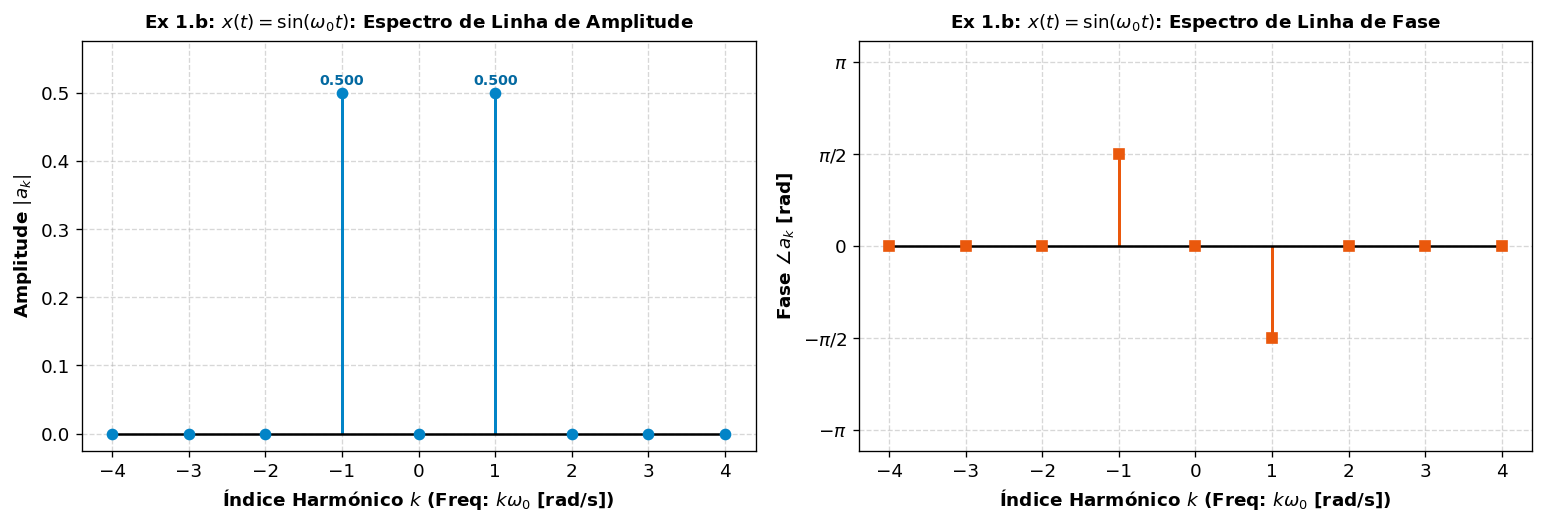

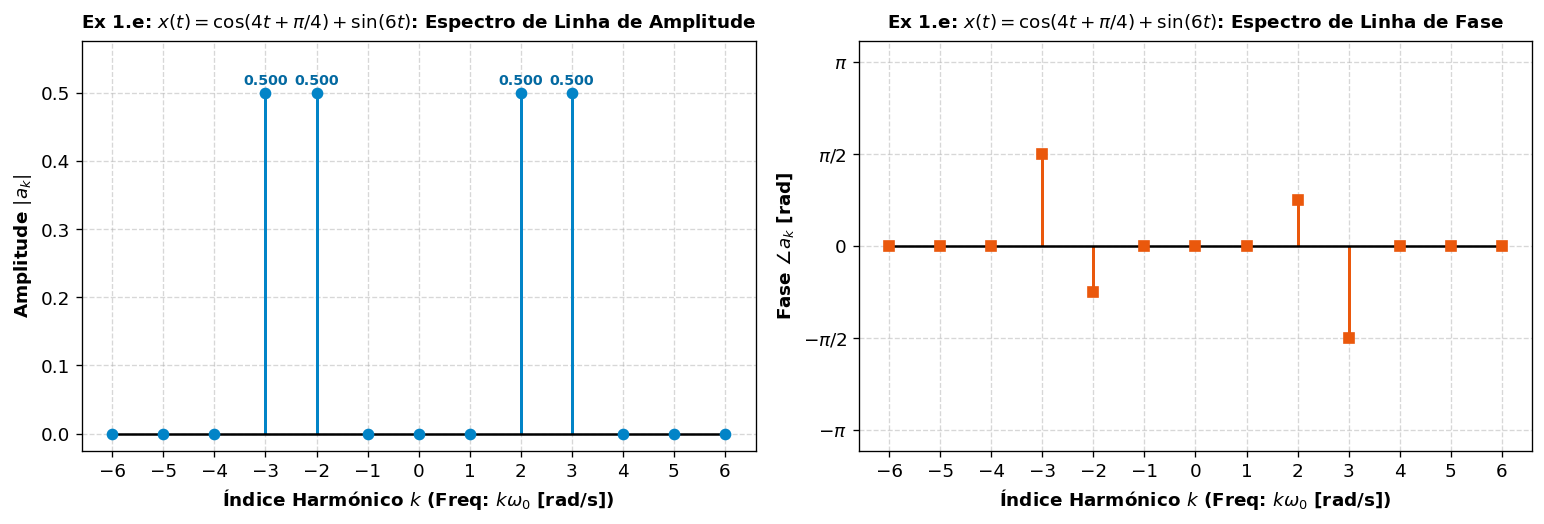

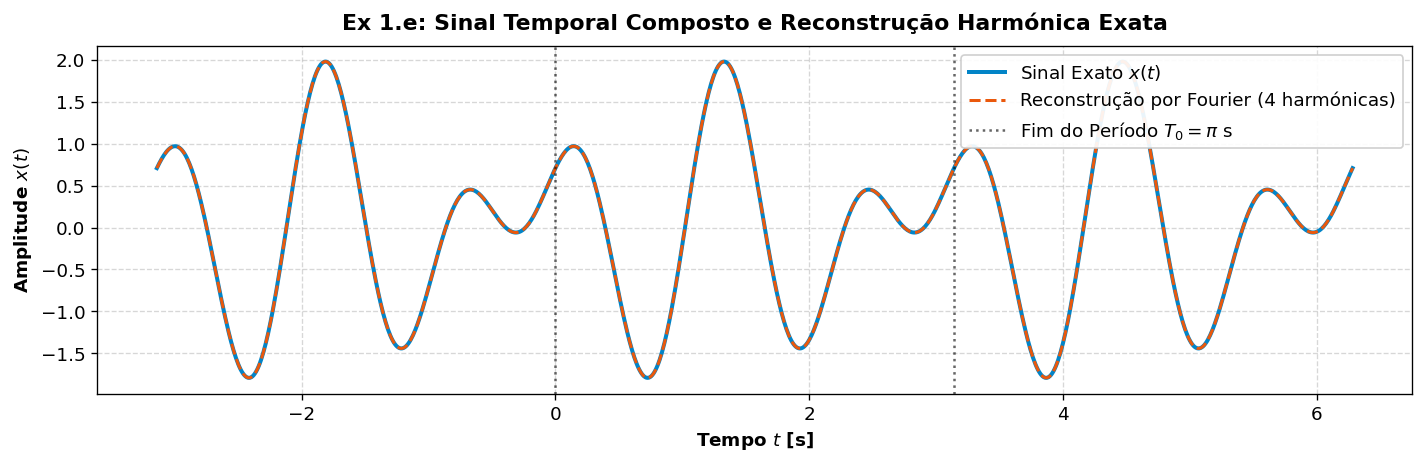

In [2]:
# ====================================================================
# SIMULAÇÃO COMPUTACIONAL & VERIFICAÇÃO SIMBÓLICA - Exercício 1
# ====================================================================

# 1. Verificação Simbólica Rigorosa com SymPy
t_sym = sp.Symbol('t', real=True)
w0_sym = sp.Symbol('w0', positive=True)

# 1.b) x(t) = sin(w0*t)
x_1b_sym = sp.sin(w0_sym * t_sym)
x_1b_euler = sp.expand(x_1b_sym.rewrite(sp.exp))
print("--- Exercício 1.b) ---")
print(f"Expressão original: x(t) = {x_1b_sym}")
print(f"Forma de Euler:     x(t) = {x_1b_euler}")

# 1.e) x(t) = cos(4t + pi/4) + sin(6t)
w0_1e = 2  # gcd(4, 6) = 2 rad/s
T0_1e = np.pi
x_1e_sym = sp.cos(4*t_sym + sp.pi/4) + sp.sin(6*t_sym)
x_1e_euler = sp.expand(x_1e_sym.rewrite(sp.exp))
print("\n--- Exercício 1.e) ---")
print(f"Frequência fundamental calculada: w0 = {w0_1e} rad/s (T0 = {T0_1e:.4f} s)")
print("Expressão expandida em exponenciais:")
print(f"x(t) = {x_1e_euler}")

# 2. Representação Gráfica e Espectros de Fourier para 1.b
k_1b = np.arange(-4, 5)
ak_1b = np.zeros(len(k_1b), dtype=complex)
ak_1b[k_1b == 1] = -0.5j
ak_1b[k_1b == -1] = 0.5j

fig1, _ = plot_fourier_spectra(k_1b, ak_1b, w0=1.0, title_prefix=r"Ex 1.b: $x(t) = \sin(\omega_0 t)$")

# 3. Representação Gráfica e Espectros de Fourier para 1.e
k_1e = np.arange(-6, 7)
ak_1e = np.zeros(len(k_1e), dtype=complex)
# k = 2: a2 = 0.5 * exp(j*pi/4)
ak_1e[k_1e == 2] = 0.5 * np.exp(1j * np.pi / 4)
ak_1e[k_1e == -2] = 0.5 * np.exp(-1j * np.pi / 4)
# k = 3: a3 = -0.5j
ak_1e[k_1e == 3] = -0.5j
ak_1e[k_1e == -3] = 0.5j

fig2, _ = plot_fourier_spectra(k_1e, ak_1e, w0=w0_1e, title_prefix=r"Ex 1.e: $x(t) = \cos(4t + \pi/4) + \sin(6t)$")

# 4. Traçado Temporal e Comparação
t_vals = np.linspace(-np.pi, 2*np.pi, 1000)
x_1e_time = np.cos(4*t_vals + np.pi/4) + np.sin(6*t_vals)
x_1e_rec = synthesize_fourier_series(t_vals, k_1e, ak_1e, w0=w0_1e)

fig3, ax3 = plt.subplots(figsize=(12, 4), dpi=120)
ax3.plot(t_vals, x_1e_time, label=r'Sinal Exato $x(t)$', color=COLOR_PRIMARY, linewidth=2.4)
ax3.plot(t_vals, x_1e_rec, '--', label=r'Reconstrução por Fourier (4 harmónicas)', color=COLOR_SECONDARY, linewidth=1.8)
ax3.set_xlabel('Tempo $t$ [s]', fontweight='bold')
ax3.set_ylabel('Amplitude $x(t)$', fontweight='bold')
ax3.set_title('Ex 1.e: Sinal Temporal Composto e Reconstrução Harmónica Exata', fontweight='bold', pad=10)
ax3.axvline(0, color='k', linestyle=':', alpha=0.6)
ax3.axvline(np.pi, color='k', linestyle=':', alpha=0.6, label=r'Fim do Período $T_0 = \pi$ s')
ax3.legend(loc='upper right', framealpha=0.92)
plt.tight_layout()

# 5. Verificação Numérica da Potência Média (Parseval)
p_tempo = np.mean(x_1e_time**2)
p_freq = np.sum(np.abs(ak_1e)**2)
print("\n--- Balanço Energético (Parseval) Ex 1.e ---")
print(f"Potência Média no Tempo:      P_x = {p_tempo:.6f} W")
print(f"Potência Média na Frequência: P_x = {p_freq:.6f} W")
print(f"Erro Absoluto de Parseval:    {abs(p_tempo - p_freq):.2e} W")
plt.show()


## Exercício 2

### Onda Quadrada Bipolar, Série Trigonométrica, Translação no Tempo e o Fenómeno de Gibbs

A onda quadrada é uma das formas de onda elementares de maior destaque em Engenharia Electrotécnica, omnipresente em sinais de relógio (*clocks*) digitais, modulação por largura de impulso (PWM), inversores estáticos e comutação de transístores de potência.

---

### Resolução Analítica Detalhada Passo a Passo

#### Alínea 2. a) Coeficientes da Série de Fourier de $x(t)$ na Forma Exponencial

Considere o sinal $x(t)$ periódico de período $T_0$, frequência angular $\omega_0 = \frac{2\pi}{T_0}$ e amplitude $A$. No primeiro período $[0, T_0]$, tendo $x(0) = A$ e ciclo de trabalho de 50%, o sinal bipolar define-se por:
$$x(t) = \begin{cases} +A, & 0 < t < T_0/2 \\ -A, & T_0/2 < t < T_0 \end{cases}$$
(nos pontos de descontinuidade $t = 0, T_0/2, T_0$, a convergência de Dirichlet garante a convergência para a média dos limites laterais, $\frac{A + (-A)}{2} = 0$).

##### 1. Cálculo da Componente Contínua ($k = 0$)
$$a_0 = \frac{1}{T_0} \int_0^{T_0} x(t) \, dt = \frac{1}{T_0} \left[ \int_0^{T_0/2} A \, dt + \int_{T_0/2}^{T_0} (-A) \, dt \right] = \frac{1}{T_0} \left[ A\frac{T_0}{2} - A\frac{T_0}{2} \right] = 0$$
O sinal não tem componente DC (área positiva cancela integralmente a área negativa).

##### 2. Dedução Integral para $k \neq 0$
Aplicando a equação de análise:
$$a_k = \frac{1}{T_0} \int_0^{T_0} x(t) e^{-j k \omega_0 t} \, dt = \frac{A}{T_0} \left[ \int_0^{T_0/2} e^{-j k \omega_0 t} \, dt - \int_{T_0/2}^{T_0} e^{-j k \omega_0 t} \, dt \right]$$

Avaliando a primitiva de $e^{-j k \omega_0 t}$:
$$\int e^{-j k \omega_0 t} \, dt = -\frac{e^{-j k \omega_0 t}}{j k \omega_0}$$

* **Primeira integral** ($[0, T_0/2]$):
  $$\left[ -\frac{e^{-j k \omega_0 t}}{j k \omega_0} \right]_0^{T_0/2} = -\frac{e^{-j k \omega_0 T_0/2} - 1}{j k \omega_0} = \frac{1 - e^{-j k \pi}}{j k \omega_0}$$
  Recordando que $\omega_0 T_0 = 2\pi$, tem-se $e^{-j k \pi} = (-1)^k$:
  $$\int_0^{T_0/2} e^{-j k \omega_0 t} \, dt = \frac{1 - (-1)^k}{j k \omega_0}$$

* **Segunda integral** ($[T_0/2, T_0]$):
  $$\left[ -\frac{e^{-j k \omega_0 t}}{j k \omega_0} \right]_{T_0/2}^{T_0} = -\frac{e^{-j k \omega_0 T_0} - e^{-j k \omega_0 T_0/2}}{j k \omega_0} = -\frac{1 - (-1)^k}{j k \omega_0}$$

Subtraindo as duas parcelas:
$$a_k = \frac{A}{T_0} \left[ \frac{1 - (-1)^k}{j k \omega_0} - \left( -\frac{1 - (-1)^k}{j k \omega_0} \right) \right] = \frac{A}{T_0} \cdot \frac{2(1 - (-1)^k)}{j k \omega_0}$$

Substituindo $T_0 \omega_0 = 2\pi$:
$$a_k = \frac{2A}{j k (2\pi)} (1 - (-1)^k) = \frac{A(1 - (-1)^k)}{j \pi k}$$

##### 3. Análise da Paridade de $k$
* **Para $k$ par ($k = 2m, m \in \mathbb{Z}$)**:
  $$(-1)^k = (-1)^{2m} = 1 \implies 1 - 1 = 0 \implies \boxed{a_k = 0}$$
  (Resultado antecipado pela Simetria de Meia-Onda: $x(t - T_0/2) = -x(t)$).
* **Para $k$ ímpar ($k = 2m+1, m \in \mathbb{Z}$)**:
  $$(-1)^k = (-1)^{2m+1} = -1 \implies 1 - (-1) = 2$$
  $$a_k = \frac{2A}{j \pi k} = -j \frac{2A}{\pi k} = \frac{2A}{\pi k} e^{-j \pi/2}$$

Conclui-se formalmente:
$$\boxed{a_k = \begin{cases} 0, & k \text{ par} \\ -j \frac{2A}{\pi k} = \frac{2A}{\pi k} e^{-j\pi/2}, & k \text{ ímpar} \end{cases}}$$

---

#### Alínea 2. b) Coeficientes da Série de Fourier de $x(t)$ na Forma Trigonométrica

Recordando as fórmulas de conversão entre a forma exponencial e trigonométrica:
$$a_0 = 0$$
$$A_k = 2 \mathrm{Re}\{a_k\}, \qquad B_k = -2 \mathrm{Im}\{a_k\}$$

Como $a_k = -j \frac{2A}{\pi k}$ é puramente imaginário para todo o $k$:
* $A_k = 2 \mathrm{Re}\{a_k\} = 0, \quad \forall k \ge 1$ (reflete a simetria ímpar de $x(t)$ em relação a $t=0$).
* Para $k$ par: $B_k = 0$.
* Para $k$ ímpar:
  $$B_k = -2 \mathrm{Im}\{a_k\} = -2 \left( -\frac{2A}{\pi k} \right) = \frac{4A}{\pi k}$$

A expansão em série trigonométrica retangular resulta em:
$$\boxed{x(t) = \sum_{k=1, 3, 5, \dots}^{\infty} \frac{4A}{\pi k} \sin(k \omega_0 t) = \frac{4A}{\pi} \left[ \sin(\omega_0 t) + \frac{1}{3}\sin(3\omega_0 t) + \frac{1}{5}\sin(5\omega_0 t) + \frac{1}{7}\sin(7\omega_0 t) + \dots \right]}$$

* **Comentário Físico**: A onda quadrada bipolar decompõe-se numa soma infinita de senos harmónicos ímpares cujas amplitudes decrescem lentamente à taxa de $1/k$. A presença exclusiva de harmónicas ímpares é a assinatura universal de distorção por simetria de meia-onda em transformadores e amplificadores classe B/AB saturados.

---

#### Alínea 2. e) Determinação dos Coeficientes de $w(t)$ por Propriedades da Série

Considere o sinal $w(t)$ definido por:
$$w(t) = \begin{cases} +1, & -T_0/4 < t \le T_0/4 \\ -1, & T_0/4 < t \le 3T_0/4 \end{cases}$$

##### 1. Relação Estrutural entre $w(t)$ e $x(t)$
Analisando atentamente $w(t)$ e comparando com $x(t)$:
* $w(t)$ tem amplitude unitária ($A = 1$).
* $w(t)$ vale $+1$ centrado na origem $t=0$ (entre $-T_0/4$ e $+T_0/4$).
* $x(t)$ valia $+A$ entre $0$ e $T_0/2$ (centrado em $t = T_0/4$).

Conclui-se que $w(t)$ corresponde a $x(t)$ com amplitude normalizada $A=1$ e **avançado no tempo de $t_0 = -T_0/4$** (deslocado para a esquerda):
$$\boxed{w(t) = \frac{1}{A} x\left(t + \frac{T_0}{4}\right) \quad \text{com } A=1}$$

##### 2. Aplicação das Propriedades da Série de Fourier
Não é necessário calcular qualquer integral! Recorre-se às duas propriedades operatórias fundamentais:
1. **Linearidade / Escalonamento em Amplitude**: $\mathcal{FS}\left\{\frac{1}{A} x(t)\right\} = \frac{1}{A} a_k$.
2. **Deslocamento no Tempo (*Time-Shifting*)**:
   Se $x(t) \stackrel{\mathcal{FS}}{\longleftrightarrow} a_k$, então:
   $$\mathcal{FS}\{x(t - t_d)\} = a_k \, e^{-j k \omega_0 t_d}$$
   No nosso caso, o avanço temporal é $t_d = -\frac{T_0}{4}$:
   $$e^{-j k \omega_0 (-T_0/4)} = e^{j k \omega_0 \frac{T_0}{4}} = e^{j k \left(\frac{2\pi}{T_0}\right) \left(\frac{T_0}{4}\right)} = e^{j k \frac{\pi}{2}} = \left(e^{j\pi/2}\right)^k = j^k$$

Designando por $c_k$ os coeficientes exponenciais de $w(t)$:
$$c_k = \frac{1}{A} a_k \, e^{j k \pi/2} = \frac{1}{A} a_k \, j^k$$

##### 3. Determinação Explícita dos Coeficientes Exponenciais $c_k$
* Para $k$ par: $a_k = 0 \implies c_k = 0$.
* Para $k=0$: $c_0 = 0$.
* Para $k$ ímpar ($k = 2m+1, m \in \mathbb{Z}$):
  $$c_k = \frac{1}{A} \left( \frac{2A}{j \pi k} \right) j^k = \frac{2}{\pi k} \frac{j^k}{j} = \frac{2}{\pi k} j^{k-1}$$
  Como $k = 2m+1$, tem-se $k-1 = 2m$, logo:
  $$j^{k-1} = j^{2m} = (j^2)^m = (-1)^m = (-1)^{\frac{k-1}{2}}$$

Substituindo:
$$\boxed{c_k = \begin{cases} 0, & k \text{ par} \\ \frac{2}{\pi k} (-1)^{\frac{k-1}{2}}, & k \text{ ímpar} \end{cases}}$$

Avaliando para as primeiras harmónicas:
* $k = 1$: $c_1 = \frac{2}{\pi(1)} (-1)^0 = \frac{2}{\pi} \approx 0.6366$
* $k = -1$: $c_{-1} = \frac{2}{\pi(-1)} (-1)^{-1} = \frac{2}{\pi} = c_1$
* $k = 3$: $c_3 = \frac{2}{\pi(3)} (-1)^1 = -\frac{2}{3\pi} \approx -0.2122$
* $k = -3$: $c_{-3} = \frac{2}{\pi(-3)} (-1)^{-2} = -\frac{2}{3\pi} = c_3$
* $k = 5$: $c_5 = \frac{2}{5\pi}$, $c_{-5} = \frac{2}{5\pi}$

* **Observação Estrutural**: Todos os coeficientes $c_k$ são **estritamente reais e pares** ($c_k = c_{-k} \in \mathbb{R}$). Isto confirma com absoluta perfeição que $w(t)$ possui **simetria par** ($w(-t) = w(t)$)! A translação temporal de um quarto de período converteu uma onda com simetria ímpar numa onda com simetria par.

##### 4. Coeficientes Trigonométricos de $w(t)$
Como $w(t)$ é par:
* $B_k = 0, \quad \forall k \ge 1$ (não existem termos em seno).
* $a_0 = c_0 = 0$.
* Para $k$ ímpar:
  $$A_k = 2 c_k = \frac{4}{\pi k} (-1)^{\frac{k-1}{2}}$$

Portanto, a série trigonométrica de $w(t)$ é composta exclusivamente por cossenos:
$$\boxed{w(t) = \sum_{k=1, 3, 5, \dots}^{\infty} \frac{4}{\pi k} (-1)^{\frac{k-1}{2}} \cos(k \omega_0 t) = \frac{4}{\pi} \left[ \cos(\omega_0 t) - \frac{1}{3}\cos(3\omega_0 t) + \frac{1}{5}\cos(5\omega_0 t) - \frac{1}{7}\cos(7\omega_0 t) + \dots \right]}$$

---

### Articulação com o Simulador Interativo (`square_wave_fourier_lab.ipynb`)
No laboratório interativo `square_wave_fourier_lab.ipynb`, a onda quadrada parametrizada por ciclo de trabalho $D$ e atraso temporal $\tau$ tem coeficientes:
$$c_n = \frac{A\left(1 - e^{-j2\pi n D}\right)}{j\pi n} e^{-j n \omega_0 \tau}$$
Fazendo $D = 0.5$ e $\tau = 0$, recupera-se instantaneamente o nosso $x(t)$: $c_n = \frac{2A}{j\pi n}$.
Fazendo $\tau = -T_0/4$, o fator de fase introduz a rotação exata $e^{jn\pi/2}$ que calculámos analiticamente para $w(t)$. Os alunos podem recorrer diretamente a esse simulador para inspecionar dinamicamente o efeito do atraso temporal e da variação do duty cycle.


Modo interativo não suportado no ambiente de execução estático (No module named 'ipywidgets'). Os gráficos estáticos acima cobrem a análise.


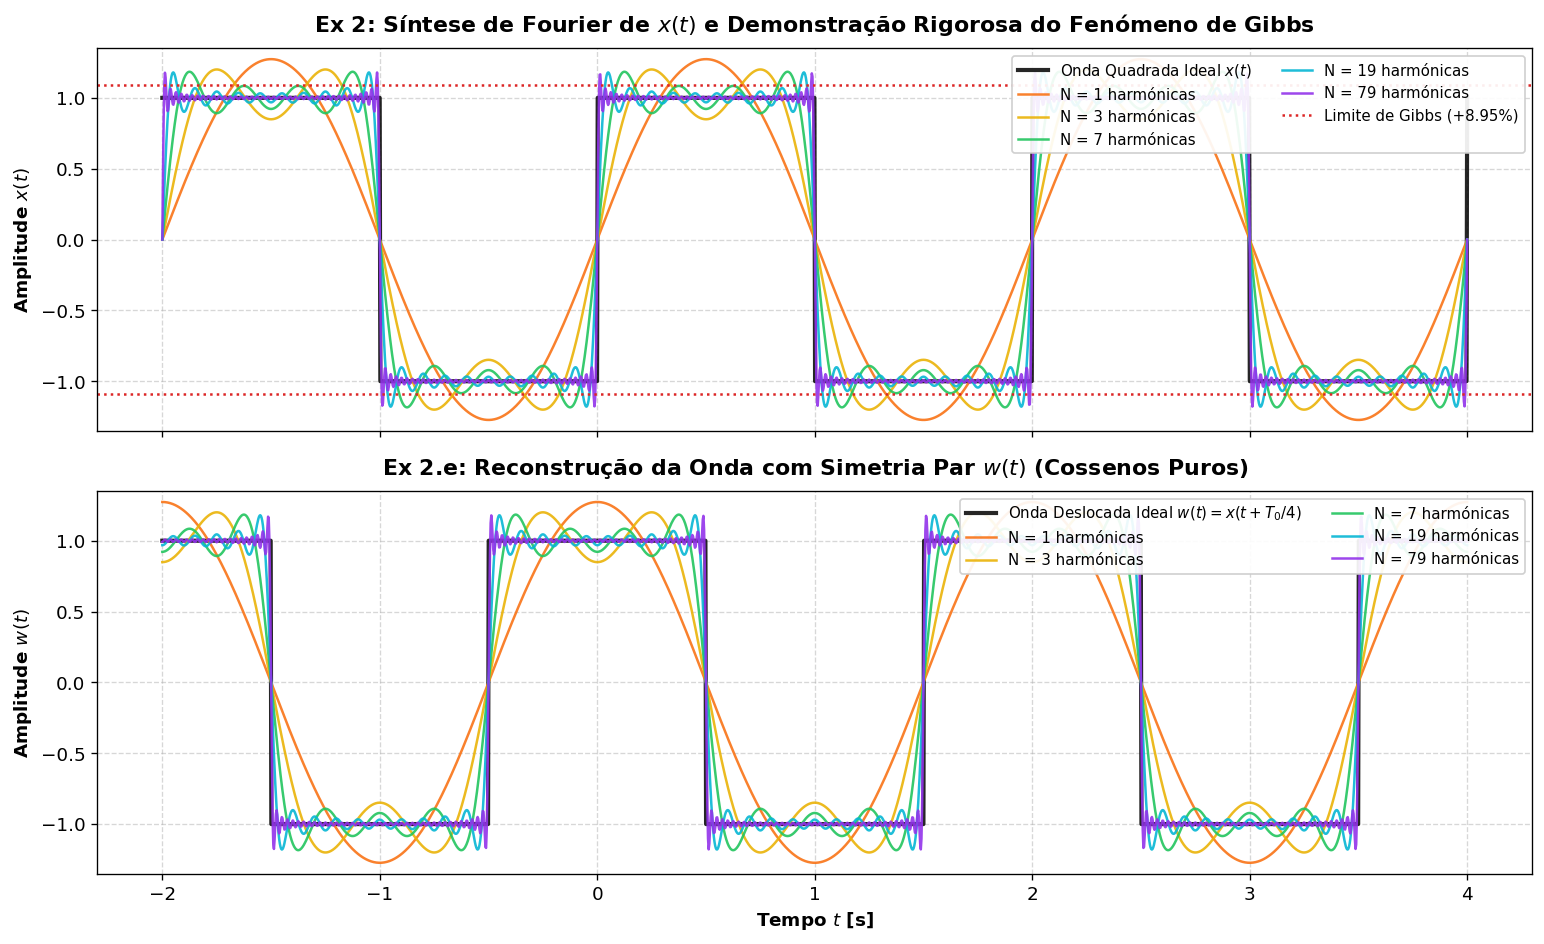

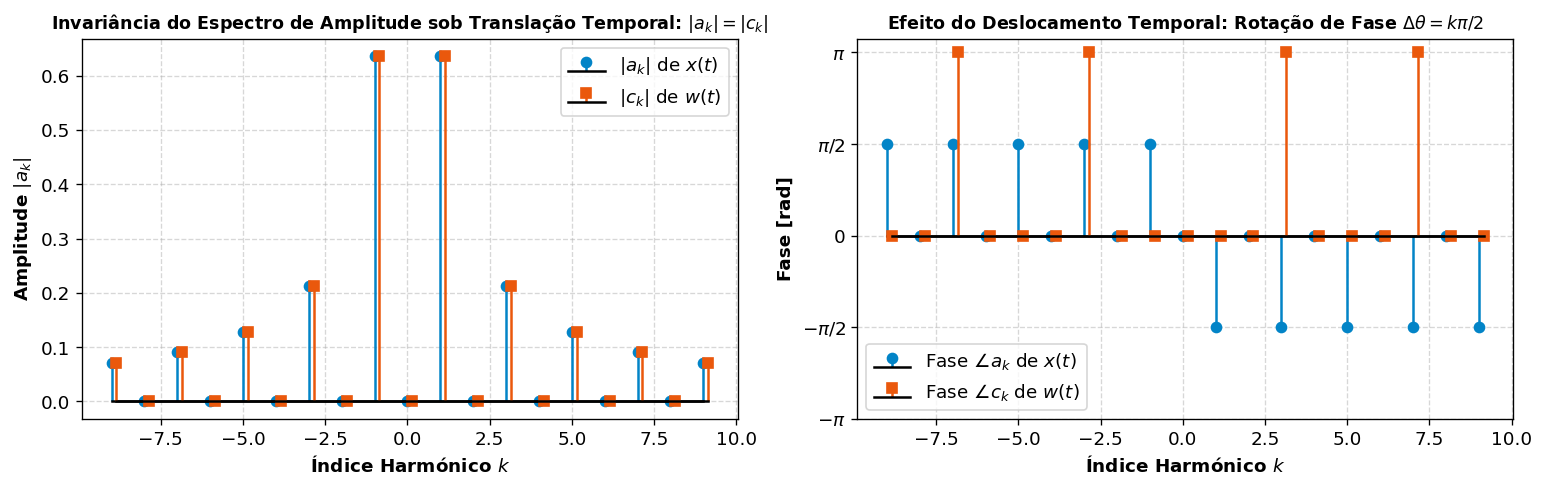

In [3]:
# ====================================================================
# SIMULAÇÃO COMPUTACIONAL, SÍNTESE HARMÓNICA & FENÓMENO DE GIBBS - Exercício 2
# ====================================================================

# 1. Definição dos Parâmetros Temporais
A = 1.0          # Amplitude normalizada
T0 = 2.0         # Período fundamental em segundos
w0 = 2 * np.pi / T0
t_sim = np.linspace(-T0, 2*T0, 2000)

# 2. Definição Analítica dos Sinais no Tempo
# x(t): Onda quadrada ímpar (+A em [0, T0/2], -A em [T0/2, T0])
x_ideal = A * signal.square(w0 * t_sim)

# w(t): Onda quadrada par (+1 em [-T0/4, T0/4], -1 em [T0/4, 3T0/4])
# Obtida avançando x(t) em T0/4
w_ideal = signal.square(w0 * (t_sim + T0/4))

# 3. Função de Síntese para Somas Parciais de Fourier da Onda Quadrada
def square_wave_reconstruction(t, A_amp, w_fund, N_harmonics, wave_type='x'):
    # Reconstrói a onda quadrada até à N-ésima harmónica.
    x_synth = np.zeros_like(t)
    for n in range(1, N_harmonics + 1, 2):  # Apenas harmónicas ímpares
        if wave_type == 'x':
            x_synth += (4 * A_amp / (np.pi * n)) * np.sin(n * w_fund * t)
        elif wave_type == 'w':
            m = (n - 1) // 2
            sign = (-1)**m
            x_synth += (4 * A_amp / (np.pi * n)) * sign * np.cos(n * w_fund * t)
    return x_synth

# 4. Estudo da Convergência e Demonstração do Fenómeno de Gibbs
harmonics_to_test = [1, 3, 7, 19, 79]
colors = ['#f97316', '#eab308', '#22c55e', '#06b6d4', '#9333ea']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), dpi=120, sharex=True)

# Painel 1: Reconstrução de x(t) (soma de senos)
ax1.plot(t_sim, x_ideal, color='black', linewidth=2.5, alpha=0.85, label=r'Onda Quadrada Ideal $x(t)$')
for nh, col in zip(harmonics_to_test, colors):
    rec = square_wave_reconstruction(t_sim, A, w0, nh, wave_type='x')
    ax1.plot(t_sim, rec, label=f'N = {nh} harmónicas', color=col, linewidth=1.5, alpha=0.9)

# Anotação do Fenómeno de Gibbs (Sobreelevação de ~8.95%)
gibbs_peak = A * (1.0 + 0.0895)
ax1.axhline(gibbs_peak, color='#dc2626', linestyle=':', linewidth=1.5, label='Limite de Gibbs (+8.95%)')
ax1.axhline(-gibbs_peak, color='#dc2626', linestyle=':', linewidth=1.5)
ax1.set_ylabel(r'Amplitude $x(t)$', fontweight='bold')
ax1.set_title(r'Ex 2: Síntese de Fourier de $x(t)$ e Demonstração Rigorosa do Fenómeno de Gibbs', fontweight='bold', pad=10)
ax1.set_ylim(-1.35 * A, 1.35 * A)
ax1.legend(loc='upper right', framealpha=0.92, fontsize=9, ncol=2)

# Painel 2: Reconstrução de w(t) (soma de cossenos alternados - Ex 2.e)
ax2.plot(t_sim, w_ideal, color='black', linewidth=2.5, alpha=0.85, label=r'Onda Deslocada Ideal $w(t) = x(t + T_0/4)$')
for nh, col in zip(harmonics_to_test, colors):
    rec_w = square_wave_reconstruction(t_sim, 1.0, w0, nh, wave_type='w')
    ax2.plot(t_sim, rec_w, label=f'N = {nh} harmónicas', color=col, linewidth=1.5, alpha=0.9)

ax2.set_xlabel('Tempo $t$ [s]', fontweight='bold')
ax2.set_ylabel(r'Amplitude $w(t)$', fontweight='bold')
ax2.set_title(r'Ex 2.e: Reconstrução da Onda com Simetria Par $w(t)$ (Cossenos Puros)', fontweight='bold', pad=10)
ax2.set_ylim(-1.35, 1.35)
ax2.legend(loc='upper right', framealpha=0.92, fontsize=9, ncol=2)

plt.tight_layout()
plt.show()

# 5. Comparação Espectral dos Coeficientes: x(t) vs w(t)
k_spec = np.arange(-9, 10)
ak_x = np.zeros(len(k_spec), dtype=complex)
ck_w = np.zeros(len(k_spec), dtype=complex)

for i, ki in enumerate(k_spec):
    if ki % 2 != 0:
        ak_x[i] = -2j * A / (np.pi * ki)
        m = (ki - 1) // 2
        sign_m = 1 if (m % 2 == 0) else -1
        ck_w[i] = (2.0 / (np.pi * ki)) * sign_m

fig_spec, (ax_s1, ax_s2) = plt.subplots(1, 2, figsize=(13, 4.2), dpi=120)
ax_s1.stem(k_spec, np.abs(ak_x), linefmt='#0284c7', markerfmt='o', basefmt='k-', label=r'$|a_k|$ de $x(t)$')
ax_s1.stem(k_spec + 0.15, np.abs(ck_w), linefmt='#ea580c', markerfmt='s', basefmt='k-', label=r'$|c_k|$ de $w(t)$')
ax_s1.set_xlabel(r'Índice Harmónico $k$', fontweight='bold')
ax_s1.set_ylabel(r'Amplitude $|a_k|$', fontweight='bold')
ax_s1.set_title(r'Invariância do Espectro de Amplitude sob Translação Temporal: $|a_k| = |c_k|$', fontsize=10.5, fontweight='bold')
ax_s1.legend()

phase_x = np.angle(ak_x)
phase_w = np.angle(ck_w)
phase_x[np.abs(ak_x) < 1e-6] = 0
phase_w[np.abs(ck_w) < 1e-6] = 0

ax_s2.stem(k_spec, phase_x, linefmt='#0284c7', markerfmt='o', basefmt='k-', label=r'Fase $\angle a_k$ de $x(t)$')
ax_s2.stem(k_spec + 0.15, phase_w, linefmt='#ea580c', markerfmt='s', basefmt='k-', label=r'Fase $\angle c_k$ de $w(t)$')
ax_s2.set_xlabel(r'Índice Harmónico $k$', fontweight='bold')
ax_s2.set_ylabel('Fase [rad]', fontweight='bold')
ax_s2.set_title(r'Efeito do Deslocamento Temporal: Rotação de Fase $\Delta\theta = k\pi/2$', fontsize=10.5, fontweight='bold')
ax_s2.set_yticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
ax_s2.set_yticklabels([r'$-\pi$', r'$-\pi/2$', r'$0$', r'$\pi/2$', r'$\pi$'])
ax_s2.legend()
plt.tight_layout()
plt.show()

# 6. Simulador Interativo (com ipywidgets se disponível, ou demonstração estática)
try:
    import ipywidgets as widgets
    from IPython.display import display
    
    def interactive_fourier_demo(N_harm=5, shift_fraction=0.0):
        t_w = np.linspace(-T0, T0, 1000)
        t_shift = shift_fraction * T0
        sig_ideal = signal.square(w0 * (t_w - t_shift))
        
        # Síntese com atraso
        rec_sig = np.zeros_like(t_w)
        for n in range(1, N_harm + 1, 2):
            cn = (2.0 / (1j * np.pi * n)) * np.exp(-1j * n * w0 * t_shift)
            rec_sig += 2 * np.real(cn * np.exp(1j * n * w0 * t_w))
            
        plt.figure(figsize=(10, 3.8), dpi=110)
        plt.plot(t_w, sig_ideal, 'k--', label='Onda Quadrada Alvo', alpha=0.7)
        plt.plot(t_w, rec_sig, color='#0284c7', linewidth=2, label=f'Síntese (N={N_harm} harmónicas)')
        plt.title(f'Simulador Interativo: N = {N_harm} Harmónicas | Atraso $\\tau = {shift_fraction:.2f} T_0$', fontweight='bold')
        plt.xlabel('Tempo [s]')
        plt.ylabel('Amplitude')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.legend(loc='upper right')
        plt.ylim(-1.4, 1.4)
        plt.show()
        
    print("Controlo Interativo Disponível via ipywidgets (arraste os cursores no Jupyter):")
    widgets.interact(interactive_fourier_demo, 
                     N_harm=widgets.IntSlider(min=1, max=51, step=2, value=7, description='Harmónicas:'),
                     shift_fraction=widgets.FloatSlider(min=-0.5, max=0.5, step=0.05, value=0.0, description=r'Atraso $\tau/T_0$:'))
except Exception as e:
    print(f"Modo interativo não suportado no ambiente de execução estático ({e}). Os gráficos estáticos acima cobrem a análise.")


## Exercício 7

### Série de Fourier da Sinusóide Retificada de Onda Completa: $$x(t) = |\sin(t)|$$

Em Engenharia Electrotécnica, a retificação de onda completa monofásica (implementada com pontes de díodos de Graetz) é o bloco fundamental de conversão AC-DC presente em todas as fontes de alimentação lineares e comutadas. A análise espectral de $|\sin(t)|$ permite dimensionar filtros de alisamento $LC$, calcular o fator de ondulação (*ripple factor*) e quantificar a componente contínua útil extraída da rede de corrente alternada.

---

### Resolução Analítica Detalhada Passo a Passo

#### 1. Análise da Periodicidade e Frequência Fundamental (Cuidado com a Armadilha!)
* O sinal sinusoidal original $s(t) = \sin(t)$ possui período $T = 2\pi\text{ s}$ e frequência $\omega = 1\text{ rad/s}$.
* Contudo, a operação de retificação por valor absoluto $|\cdot|$ inverte os semiciclos negativos, tornando-os idênticos aos positivos.
* Assim, a forma de onda **repete-se exatamente a cada $\pi$ radianos**:
  $$\boxed{T_0 = \pi \text{ s}}$$
* A **frequência angular fundamental** de $x(t)$ é, portanto, o dobro da frequência da sinusóide original:
  $$\boxed{\omega_0 = \frac{2\pi}{T_0} = \frac{2\pi}{\pi} = 2 \text{ rad/s}}$$
*(Nota Pedagógica: Esta duplicação da frequência fundamental é a razão pela qual as fontes retificadas de 50 Hz em Portugal apresentam uma ondulação típica de 100 Hz).*

#### 2. Análise de Simetrias
* **Simetria Par**:
  $$x(-t) = |\sin(-t)| = |-\sin(t)| = |\sin(t)| = x(t)$$
  Sendo uma função par, os coeficientes $a_k$ da Série Exponencial são **estritamente reais** e a Série Trigonométrica é composta **exclusivamente por cossenos** ($B_k = 0, \forall k$).

#### 3. Cálculo da Componente Contínua ($a_0$)
Escolhendo o período de integração $[0, \pi]$, onde $\sin(t) \ge 0$, temos $|\sin(t)| = \sin(t)$:
$$a_0 = \frac{1}{T_0} \int_0^{T_0} x(t) \, dt = \frac{1}{\pi} \int_0^\pi \sin(t) \, dt = \frac{1}{\pi} \left[ -\cos(t) \right]_0^\pi = \frac{1}{\pi} \left[ -(-1) - (-1) \right] = \frac{2}{\pi}$$
$$\boxed{a_0 = \frac{2}{\pi} \approx 0.63662}$$
* **Significado em Engenharia**: $V_{\text{DC}} = \frac{2}{\pi} V_{\text{max}} \approx 63.66\%$ da tensão de pico da entrada sinusoidal.

#### 4. Dedução Integral dos Coeficientes Exponenciais $a_k$ ($k \in \mathbb{Z}$)
Aplicando a equação de análise com $\omega_0 = 2$:
$$a_k = \frac{1}{T_0} \int_0^{T_0} x(t) e^{-j k \omega_0 t} \, dt = \frac{1}{\pi} \int_0^\pi \sin(t) e^{-j 2 k t} \, dt$$

Substituindo $\sin(t) = \frac{e^{jt} - e^{-jt}}{2j}$:
$$a_k = \frac{1}{2\pi j} \int_0^\pi \left( e^{jt} - e^{-jt} \right) e^{-j 2kt} \, dt = \frac{1}{2\pi j} \int_0^\pi \left( e^{j(1 - 2k)t} - e^{-j(1 + 2k)t} \right) \, dt$$

Avaliando cada uma das integrais:
* **Primeira parcela**:
  $$\int_0^\pi e^{j(1 - 2k)t} \, dt = \left[ \frac{e^{j(1 - 2k)t}}{j(1 - 2k)} \right]_0^\pi = \frac{e^{j\pi} e^{-j 2k\pi} - 1}{j(1 - 2k)}$$
  Como $e^{j\pi} = -1$ e $e^{-j 2k\pi} = 1$ para todo o $k$ inteiro:
  $$\int_0^\pi e^{j(1 - 2k)t} \, dt = \frac{-1 - 1}{j(1 - 2k)} = \frac{-2}{j(1 - 2k)}$$

* **Segunda parcela**:
  $$\int_0^\pi e^{-j(1 + 2k)t} \, dt = \left[ \frac{e^{-j(1 + 2k)t}}{-j(1 + 2k)} \right]_0^\pi = \frac{e^{-j\pi} e^{-j 2k\pi} - 1}{-j(1 + 2k)} = \frac{-1 - 1}{-j(1 + 2k)} = \frac{2}{j(1 + 2k)}$$

Subtraindo as duas parcelas:
$$\int_0^\pi \left( e^{j(1 - 2k)t} - e^{-j(1 + 2k)t} \right) \, dt = -\frac{2}{j(1 - 2k)} - \frac{2}{j(1 + 2k)} = \frac{2}{j} \left[ -\frac{1}{1 - 2k} - \frac{1}{1 + 2k} \right]$$
Reduzindo ao mesmo denominador:
$$-\frac{1}{1 - 2k} - \frac{1}{1 + 2k} = \frac{-(1 + 2k) - (1 - 2k)}{(1 - 2k)(1 + 2k)} = \frac{-2}{1 - 4k^2}$$
Portanto, a integral resulta em:
$$\frac{2}{j} \left( \frac{-2}{1 - 4k^2} \right) = -\frac{4}{j(1 - 4k^2)} = \frac{4j}{1 - 4k^2}$$

Multiplicando pelo fator exterior $\frac{1}{2\pi j}$:
$$a_k = \frac{1}{2\pi j} \cdot \frac{4j}{1 - 4k^2} = \frac{2}{\pi (1 - 4k^2)}$$

Conclui-se a expressão analítica fechada para todos os $k \in \mathbb{Z}$:
$$\boxed{a_k = \frac{2}{\pi (1 - 4k^2)}, \quad \forall k \in \mathbb{Z}}$$

* **Verificação para $k=0$**:
  $$a_0 = \frac{2}{\pi (1 - 0)} = \frac{2}{\pi} \quad \text{(Idêntico ao valor médio calculado anteriormente!)}$$
* **Verificação dos primeiros coeficientes**:
  * $k = \pm 1$: $a_1 = a_{-1} = \frac{2}{\pi (1 - 4)} = -\frac{2}{3\pi} \approx -0.21221$
  * $k = \pm 2$: $a_2 = a_{-2} = \frac{2}{\pi (1 - 16)} = -\frac{2}{15\pi} \approx -0.04244$
  * $k = \pm 3$: $a_3 = a_{-3} = \frac{2}{\pi (1 - 36)} = -\frac{2}{35\pi} \approx -0.01819$
  * $k = \pm 4$: $a_4 = a_{-4} = \frac{2}{\pi (1 - 64)} = -\frac{2}{63\pi} \approx -0.01011$

#### 5. Representação na Série Trigonométrica Retangular
Como $x(t)$ é par, $B_k = 0$ para todo o $k$.
Para os coeficientes dos cossenos:
$$A_k = 2 a_k = \frac{4}{\pi(1 - 4k^2)} = -\frac{4}{\pi(4k^2 - 1)}, \quad (k \ge 1)$$

A série trigonométrica completa assume a forma canónica:
$$\boxed{x(t) = \frac{2}{\pi} - \sum_{k=1}^{\infty} \frac{4}{\pi (4k^2 - 1)} \cos(2kt) = \frac{2}{\pi} - \frac{4}{\pi} \left[ \frac{\cos(2t)}{3} + \frac{\cos(4t)}{15} + \frac{\cos(6t)}{35} + \frac{\cos(8t)}{63} + \dots \right]}$$

#### 6. Análise da Taxa de Decaimento Espectral
Repare que para valores elevados de $k$:
$$|a_k| = \frac{2}{\pi (4k^2 - 1)} \approx \frac{1}{2\pi k^2} \sim \mathcal{O}\left(\frac{1}{k^2}\right)$$
* **Por que razão decai como $1/k^2$ e não como $1/k$?**
  O sinal $|\sin(t)|$ é **estritamente contínuo** em toda a reta real (não possui descontinuidades de salto). No entanto, a sua primeira derivada $\frac{d}{dt}|\sin(t)|$ apresenta descontinuidades de salto finitas nos instantes $t = n\pi$ (onde o sinal atinge zero em bico). De acordo com o teorema de decaimento de Fourier, uma função contínua cuja derivada de primeira ordem é descontínua possui coeficientes harmónicos que decaem à taxa assintótica de $\frac{1}{k^2}$.
  Consequentemente, a Série de Fourier de $|\sin(t)|$ converge **muito mais rapidamente** e **não exibe o Fenómeno de Gibbs** (convergência uniforme).


--- Confirmação Simbólica com SymPy (Ex 7) ---
Expressão deduzida simbolicamente para a_k:
     -2      
-------------
   /   2    \
pi*\4*k  - 1/
Avaliação para k=0: a_0 = 2/pi = 0.63662
Avaliação para k=1: a_1 = -2/(3*pi) = -0.21221


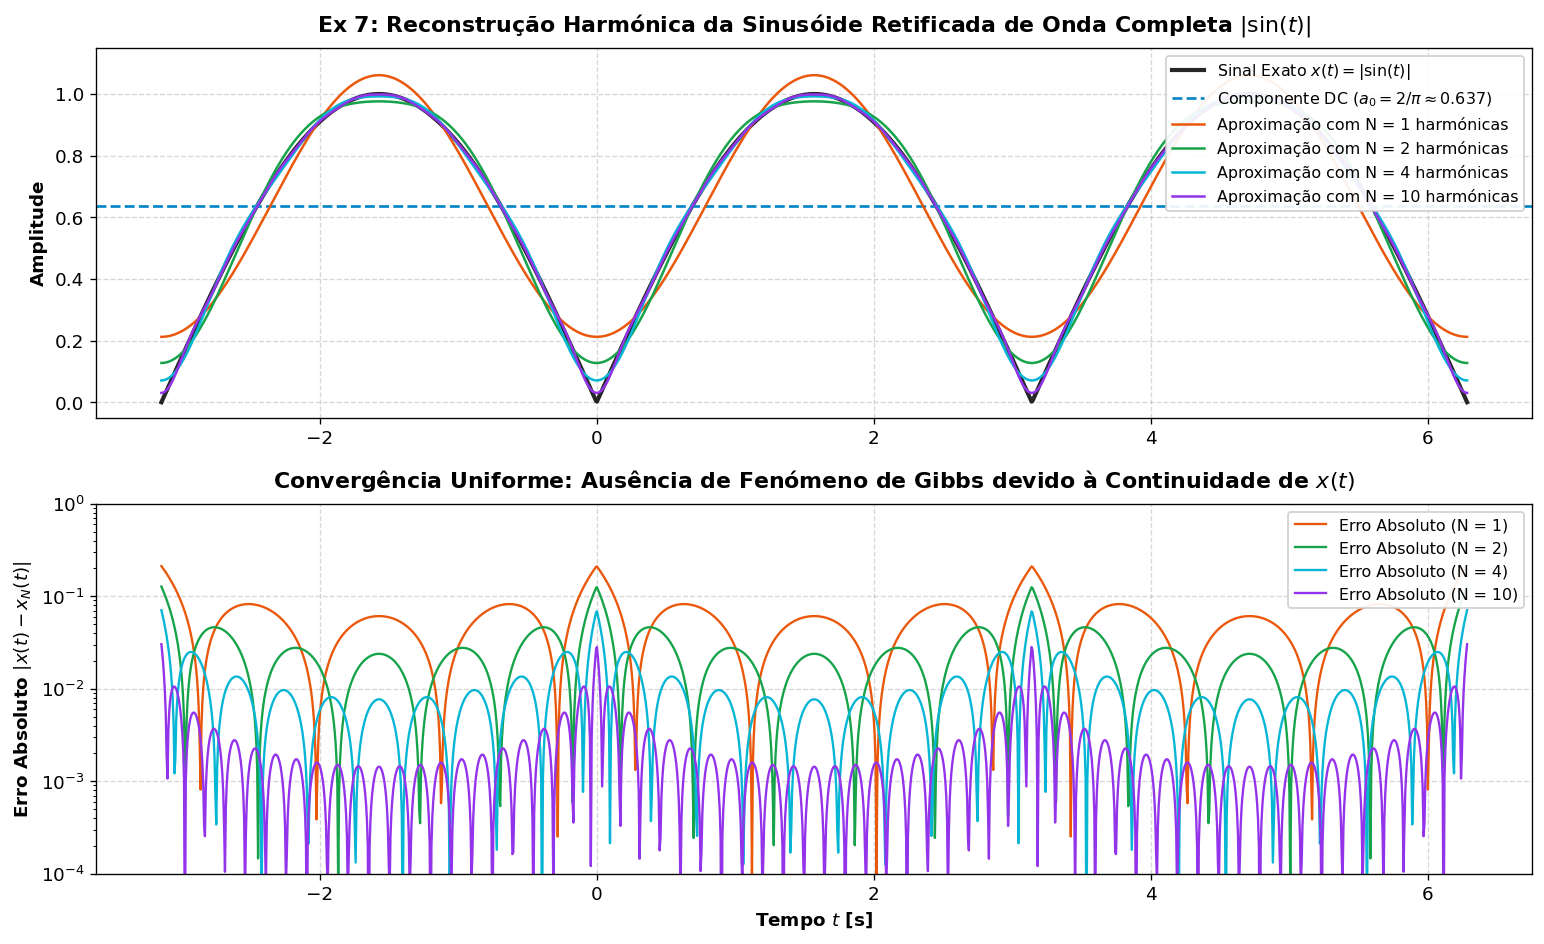

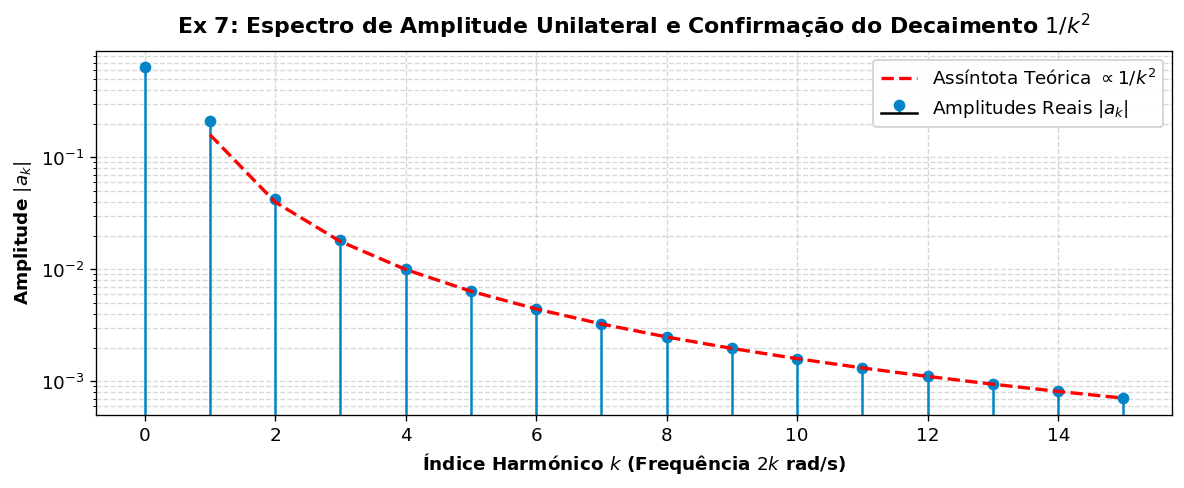

In [4]:
# ====================================================================
# SIMULAÇÃO COMPUTACIONAL & SÍNTESE ESPECTRAL - Exercício 7
# ====================================================================

# 1. Integração Simbólica com SymPy para Confirmação Analítica
t_sp = sp.Symbol('t', real=True)
k_sp = sp.Symbol('k', integer=True)

# a_k = (1/pi) * integral_0^pi sin(t) * exp(-2j*k*t) dt
integrand = sp.sin(t_sp) * sp.exp(-sp.I * 2 * k_sp * t_sp)
ak_sp = (1 / sp.pi) * sp.integrate(integrand, (t_sp, 0, sp.pi))
ak_sp_simplified = sp.simplify(ak_sp)

print("--- Confirmação Simbólica com SymPy (Ex 7) ---")
print("Expressão deduzida simbolicamente para a_k:")
sp.pprint(ak_sp_simplified)
print(f"Avaliação para k=0: a_0 = {ak_sp_simplified.subs(k_sp, 0)} = {float(ak_sp_simplified.subs(k_sp, 0)):.5f}")
print(f"Avaliação para k=1: a_1 = {ak_sp_simplified.subs(k_sp, 1)} = {float(ak_sp_simplified.subs(k_sp, 1)):.5f}")

# 2. Reconstrução Harmónica Numérica com Diferentes Ordens
t_ret = np.linspace(-np.pi, 2*np.pi, 1500)
x_ret_ideal = np.abs(np.sin(t_ret))

def rect_sine_reconstruction(t, N_terms):
    # Reconstrói |sin(t)| usando a componente DC e N harmónicas
    rec = (2.0 / np.pi) * np.ones_like(t)
    for k in range(1, N_terms + 1):
        rec -= (4.0 / (np.pi * (4 * k**2 - 1))) * np.cos(2 * k * t)
    return rec

orders = [1, 2, 4, 10]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), dpi=120)

# Traçado das aproximações temporais
ax1.plot(t_ret, x_ret_ideal, 'k-', linewidth=2.5, alpha=0.85, label=r'Sinal Exato $x(t) = |\sin(t)|$')
ax1.axhline(2/np.pi, color='#0284c7', linestyle='--', linewidth=1.6, label=r'Componente DC ($a_0 = 2/\pi \approx 0.637$)')

colors_ret = ['#ea580c', '#16a34a', '#06b6d4', '#9333ea']
for N, col in zip(orders, colors_ret):
    x_rec_N = rect_sine_reconstruction(t_ret, N)
    ax1.plot(t_ret, x_rec_N, label=f'Aproximação com N = {N} harmónicas', color=col, linewidth=1.5)

ax1.set_ylabel('Amplitude', fontweight='bold')
ax1.set_title(r'Ex 7: Reconstrução Harmónica da Sinusóide Retificada de Onda Completa $|\sin(t)|$', fontweight='bold', pad=10)
ax1.legend(loc='upper right', framealpha=0.92, fontsize=9.5)
ax1.set_ylim(-0.05, 1.15)

# Traçado do erro de aproximação e convergência rápida
for N, col in zip(orders, colors_ret):
    x_rec_N = rect_sine_reconstruction(t_ret, N)
    error_N = np.abs(x_ret_ideal - x_rec_N)
    ax2.plot(t_ret, error_N, label=f'Erro Absoluto (N = {N})', color=col, linewidth=1.4)

ax2.set_xlabel('Tempo $t$ [s]', fontweight='bold')
ax2.set_ylabel(r'Erro Absoluto $|x(t) - x_N(t)|$', fontweight='bold')
ax2.set_title(r'Convergência Uniforme: Ausência de Fenómeno de Gibbs devido à Continuidade de $x(t)$', fontweight='bold', pad=10)
ax2.set_yscale('log')
ax2.set_ylim(1e-4, 1.0)
ax2.legend(loc='upper right', framealpha=0.92, fontsize=9.5)

plt.tight_layout()
plt.show()

# 3. Espectro de Amplitude e Comparação da Taxa de Decaimento
k_range = np.arange(0, 16)
ak_magnitudes = [2.0 / (np.pi * (4 * k**2 - 1)) if k > 0 else 2.0 / np.pi for k in k_range]
asymptotic_decay = [0.5 / (np.pi * k**2) if k > 0 else np.nan for k in k_range]

plt.figure(figsize=(10, 4.2), dpi=120)
plt.stem(k_range, ak_magnitudes, linefmt='#0284c7', markerfmt='o', basefmt='k-', label=r'Amplitudes Reais $|a_k|$')
plt.plot(k_range[1:], asymptotic_decay[1:], 'r--', linewidth=2, label=r'Assíntota Teórica $\propto 1/k^2$')
plt.xlabel(r'Índice Harmónico $k$ (Frequência $2k$ rad/s)', fontweight='bold')
plt.ylabel(r'Amplitude $|a_k|$', fontweight='bold')
plt.title(r'Ex 7: Espectro de Amplitude Unilateral e Confirmação do Decaimento $1/k^2$', fontweight='bold', pad=10)
plt.yscale('log')
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(framealpha=0.92)
plt.tight_layout()
plt.show()


## Exercício 9

### Síntese de Fourier Inversa a partir dos Coeficientes Espectrais Complexos

Neste exercício resolve-se o **problema inverso da análise de Fourier**: dados os coeficientes complexos discretos $a_k$ e a frequência angular fundamental $\omega_0$, determinar a expressão explícita do sinal temporal $x(t)$.

---

### Resolução Analítica Detalhada Passo a Passo

#### 1. Enunciado e Dados Espectrais
São fornecidos:
* Frequência angular fundamental: $\omega_0 = 1 \text{ rad/s}$ (período fundamental $T_0 = \frac{2\pi}{\omega_0} = 2\pi \text{ s}$).
* Conjunto de coeficientes espectrais não nulos:
  $$a_{-3} = j \frac{1}{2}, \qquad a_{-2} = \frac{1}{2}, \qquad a_2 = \frac{1}{2}, \qquad a_3 = -j \frac{1}{2}$$
  $$a_k = 0, \quad \forall k \notin \{-3, -2, 2, 3\}$$

#### 2. Verificação das Condições de Realidade do Sinal
Antes de proceder à síntese, convém inspecionar a propriedade da simetria conjugada para averiguar se o sinal $x(t)$ gerado é puramente real:
* Para $k = 2$:
  $$a_{-2} = \frac{1}{2}, \qquad a_2^* = \left(\frac{1}{2}\right)^* = \frac{1}{2} \implies a_{-2} = a_2^* \quad \checkmark$$
* Para $k = 3$:
  $$a_{-3} = j\frac{1}{2}, \qquad a_3^* = \left(-j\frac{1}{2}\right)^* = j\frac{1}{2} \implies a_{-3} = a_3^* \quad \checkmark$$
Como $a_{-k} = a_k^*$ para todas as harmónicas, o sinal temporal resultante $x(t)$ é **garantidamente real** ($x(t) \in \mathbb{R}$).

#### 3. Aplicação da Equação de Síntese
A fórmula de síntese da Série de Fourier é dada por:
$$x(t) = \sum_{k=-\infty}^{+\infty} a_k \, e^{j k \omega_0 t}$$
Substituindo $\omega_0 = 1$ e os únicos quatro termos não nulos:
$$x(t) = a_{-3} e^{-j 3t} + a_{-2} e^{-j 2t} + a_2 e^{j 2t} + a_3 e^{j 3t}$$

Substituindo os valores numéricos dos coeficientes:
$$x(t) = \left(j\frac{1}{2}\right) e^{-j 3t} + \left(\frac{1}{2}\right) e^{-j 2t} + \left(\frac{1}{2}\right) e^{j 2t} + \left(-j\frac{1}{2}\right) e^{j 3t}$$

#### 4. Agrupamento em Pares Complexos Conjugados e Fórmulas Inversas de Euler
Agrupando as harmónicas de mesma frequência angular:
$$x(t) = \underbrace{\left[ \frac{1}{2} e^{j 2t} + \frac{1}{2} e^{-j 2t} \right]}_{\text{Termos de ordem } k=\pm 2} + \underbrace{\left[ -j\frac{1}{2} e^{j 3t} + j\frac{1}{2} e^{-j 3t} \right]}_{\text{Termos de ordem } k=\pm 3}$$

* **Para $k = \pm 2$**:
  Factorizando $\frac{1}{2}$:
  $$\frac{1}{2} e^{j 2t} + \frac{1}{2} e^{-j 2t} = \frac{e^{j 2t} + e^{-j 2t}}{2} = \cos(2t)$$

* **Para $k = \pm 3$**:
  Colocando $-\frac{j}{2}$ em evidência:
  $$-j\frac{1}{2} e^{j 3t} + j\frac{1}{2} e^{-j 3t} = -\frac{j}{2} \left( e^{j 3t} - e^{-j 3t} \right) = \frac{1}{2j} \left( e^{j 3t} - e^{-j 3t} \right) = \sin(3t)$$
  (repare que $-\frac{j}{2} = \frac{-j \cdot j}{2j} = \frac{1}{2j}$).

#### 5. Expressão Analítica Final
Somando ambas as parcelas trigonométricas:
$$\boxed{x(t) = \cos(2t) + \sin(3t)}$$

* **Discussão Físico-Matemática**:
  * O sinal é composto por duas sinusóides de amplitudes unitárias nas frequências $\omega = 2\text{ rad/s}$ ($k=2$) e $\omega = 3\text{ rad/s}$ ($k=3$).
  * A frequência fundamental global do sinal é $\omega_0 = \gcd(2, 3) = 1\text{ rad/s}$, conforme indicado no enunciado.
  * O coeficiente $a_1 = 0$ mostra que o sinal não contém qualquer componente na frequência fundamental de 1 rad/s, embora o seu padrão temporal se repita com período $T_0 = 2\pi\text{ s}$.
  * Trata-se exatamente da estrutura harmónica complementar à que analisámos no Exercício 1.e!


--- Verificação Simbólica da Síntese Inversa (Ex 9) ---
Expressão obtida após simplificação trigonométrica:
x(t) = -I*exp(3*I*t)/2 + exp(2*I*t)/2 + exp(-2*I*t)/2 + I*exp(-3*I*t)/2


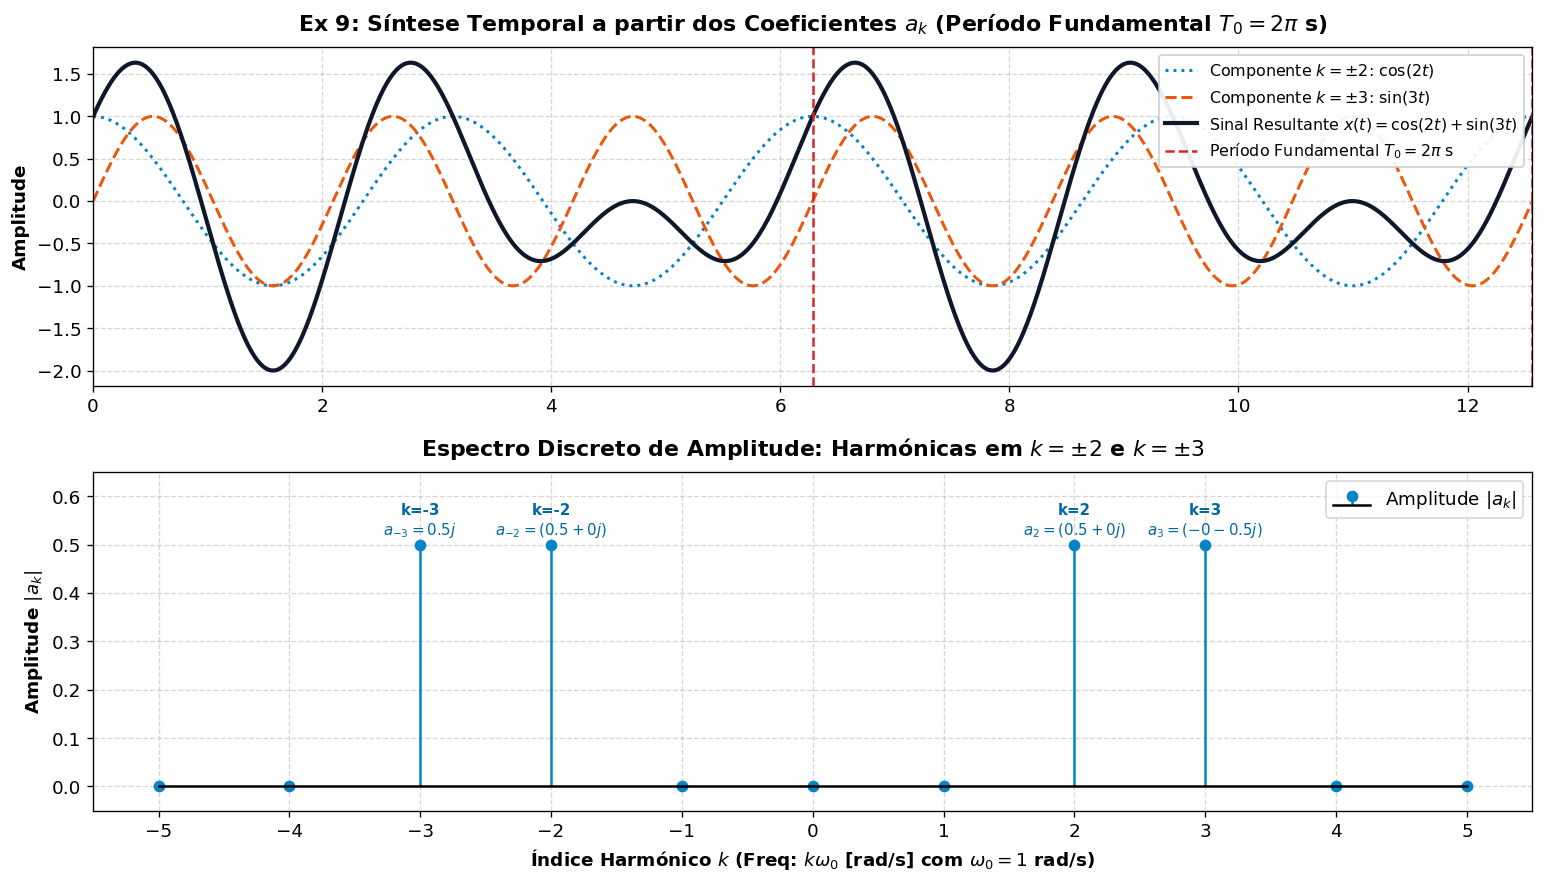

In [5]:
# ====================================================================
# SIMULAÇÃO COMPUTACIONAL & SÍNTESE TEMPORAL - Exercício 9
# ====================================================================

# 1. Verificação Simbólica com SymPy
t_sym = sp.Symbol('t', real=True)
a_m3 = sp.I / 2
a_m2 = sp.Rational(1, 2)
a_p2 = sp.Rational(1, 2)
a_p3 = -sp.I / 2

# Equação de Síntese
x_sym = a_m3 * sp.exp(-sp.I * 3 * t_sym) + a_m2 * sp.exp(-sp.I * 2 * t_sym) + \
        a_p2 * sp.exp(sp.I * 2 * t_sym) + a_p3 * sp.exp(sp.I * 3 * t_sym)

x_simplified = sp.trigsimp(sp.expand(x_sym))
print("--- Verificação Simbólica da Síntese Inversa (Ex 9) ---")
print("Expressão obtida após simplificação trigonométrica:")
print(f"x(t) = {x_simplified}")

# 2. Traçado do Sinal e das suas Componentes Harmónicas
t_vals9 = np.linspace(0, 4*np.pi, 1200)
harm_2 = np.cos(2 * t_vals9)
harm_3 = np.sin(3 * t_vals9)
x_total9 = harm_2 + harm_3

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7.5), dpi=120)

# Painel 1: Componentes e Sinal Resultante
ax1.plot(t_vals9, harm_2, ':', color='#0284c7', linewidth=1.8, label=r'Componente $k=\pm 2$: $\cos(2t)$')
ax1.plot(t_vals9, harm_3, '--', color='#ea580c', linewidth=1.8, label=r'Componente $k=\pm 3$: $\sin(3t)$')
ax1.plot(t_vals9, x_total9, color='#0f172a', linewidth=2.5, label=r'Sinal Resultante $x(t) = \cos(2t) + \sin(3t)$')

ax1.axvline(2*np.pi, color='#dc2626', linestyle='--', linewidth=1.5, label=r'Período Fundamental $T_0 = 2\pi$ s')
ax1.axvline(4*np.pi, color='#dc2626', linestyle='--', linewidth=1.5)
ax1.set_ylabel('Amplitude', fontweight='bold')
ax1.set_title(r'Ex 9: Síntese Temporal a partir dos Coeficientes $a_k$ (Período Fundamental $T_0 = 2\pi$ s)', fontweight='bold', pad=10)
ax1.legend(loc='upper right', framealpha=0.92, fontsize=9.5)
ax1.set_xlim(0, 4*np.pi)

# Painel 2: Espectro Fasorial dos Coeficientes no Plano Complexo
k_indices9 = np.array([-3, -2, 2, 3])
ak_values9 = np.array([0.5j, 0.5, 0.5, -0.5j])

k_full = np.arange(-5, 6)
ak_full = np.zeros(len(k_full), dtype=complex)
for k_val, a_val in zip(k_indices9, ak_values9):
    ak_full[k_full == k_val] = a_val

ax2.stem(k_full, np.abs(ak_full), linefmt='#0284c7', markerfmt='o', basefmt='k-', label=r'Amplitude $|a_k|$')
ax2.set_xlabel(r'Índice Harmónico $k$ (Freq: $k\omega_0$ [rad/s] com $\omega_0=1$ rad/s)', fontweight='bold')
ax2.set_ylabel(r'Amplitude $|a_k|$', fontweight='bold')
ax2.set_title(r'Espectro Discreto de Amplitude: Harmónicas em $k=\pm 2$ e $k=\pm 3$', fontweight='bold', pad=10)
ax2.set_xticks(k_full)
ax2.set_ylim(-0.05, 0.65)

for k_val, a_val in zip(k_indices9, ak_values9):
    ax2.annotate(f"k={k_val}\n$a_{{{k_val}}}={a_val}$", (k_val, np.abs(a_val)), textcoords="offset points",
                 xytext=(0, 6), ha='center', fontsize=9, fontweight='bold', color='#0369a1')

ax2.legend(loc='upper right')
plt.tight_layout()
plt.show()


---
## 2. Quadro Síntese de Todos os Exercícios Resolvidos

A tabela seguinte consolida e sistematiza os resultados obtidos em todos os exercícios da Folha Prática TP06a, oferecendo uma visão unificada essencial para preparação e consulta rápida:

| Exercício | Sinal $x(t)$ | Período $T_0$ e Freq. $\omega_0$ | Simetria | Coeficientes Exponenciais $a_k$ | Coeficientes Trigonométricos | Taxa de Decaimento Espectral | Relevância em Engenharia Electrotécnica |
| :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **1. b)** | $\sin(\omega_0 t)$ | $T_0 = \frac{2\pi}{\omega_0}$, $\omega_0$ | Real, Ímpar | $a_1 = -j/2$, $a_{-1} = j/2$, $a_k = 0 \; (k \neq \pm 1)$ | $a_0 = 0$, $A_k = 0$, $B_1 = 1$, $B_{k > 1} = 0$ | Finito (2 linhas) | Bloco elementar de modulação e geração AC |
| **1. e)** | $\cos(4t + \pi/4) + \sin(6t)$ | $T_0 = \pi\text{ s}$, $\omega_0 = 2\text{ rad/s}$ | Real | $a_{\pm 2} = \frac{1}{2} e^{\pm j\pi/4}$, $a_{\pm 3} = \mp j/2$ | $A_2 = \frac{\sqrt{2}}{2}, B_2 = -\frac{\sqrt{2}}{2}$, $A_3 = 0, B_3 = 1$ | Finito (4 linhas) | Sinais bi-harmónicos em distorção de intermodulação |
| **2. a)/b)** | Onda Quadrada Bipolar ($\pm A$) | $T_0$, $\omega_0 = \frac{2\pi}{T_0}$ | Real, Ímpar, Meia-Onda | $a_k = \begin{cases} -j\frac{2A}{\pi k}, & k \text{ ímpar} \\ 0, & k \text{ par} \end{cases}$ | $A_k = 0$, $B_k = \frac{4A}{\pi k}$ ($k$ ímpar) | $\mathcal{O}(1/k)$ (lento, saltos) | Sinais de relógio digital, comutação e inversores |
| **2. e)** | Onda Quadrada Deslocada $w(t)$ | $T_0$, $\omega_0 = \frac{2\pi}{T_0}$ | Real, Par, Meia-Onda | $c_k = \begin{cases} \frac{2}{\pi k} (-1)^{\frac{k-1}{2}}, & k \text{ ímpar} \\ 0, & k \text{ par} \end{cases}$ | $A_k = \frac{4}{\pi k} (-1)^{\frac{k-1}{2}}$, $B_k = 0$ | $\mathcal{O}(1/k)$ (lento, saltos) | Prova da conservação espectral sob translação temporal |
| **7.** | Sinusóide Retificada $|\sin(t)|$ | $T_0 = \pi\text{ s}$, $\omega_0 = 2\text{ rad/s}$ | Real, Par | $a_k = \frac{2}{\pi(1 - 4k^2)}, \; \forall k \in \mathbb{Z}$ | $a_0 = \frac{2}{\pi}$, $A_k = -\frac{4}{\pi(4k^2-1)}$, $B_k = 0$ | $\mathcal{O}(1/k^2)$ (rápido, contínuo) | Retificação de onda completa e filtragem AC-DC |
| **9.** | Síntese de $a_{\pm 2}=0.5$, $a_{\pm 3}=\mp j 0.5$ | $T_0 = 2\pi\text{ s}$, $\omega_0 = 1\text{ rad/s}$ | Real | $a_{\pm 2} = 0.5$, $a_3 = -j/2$, $a_{-3} = j/2$ | $x(t) = \cos(2t) + \sin(3t)$ | Finito (4 linhas) | Síntese inversa em analisadores de espectro |

---

## 3. Recomendações e Conclusões Pedagógicas do Docente

Como docente responsável, saliento aos futuros Engenheiros Electrotécnicos os seguintes aspetos críticos:

1. **Identificação da Frequência Fundamental $\omega_0$**:
   Antes de calcular qualquer integral, determine sem erro a menor frequência angular comum $\omega_0 = \gcd(\omega_1, \omega_2, \dots)$. Lembre-se do Exercício 7: a retificação duplica a frequência fundamental ($T_0$ passa de $2\pi$ para $\pi$), um erro clássico em exames!
2. **Aproveitamento das Fórmulas de Euler**:
   Sempre que o sinal for composto por produtos ou somas de funções trigonométricas, **nunca integre**! A expansão por Euler é dez vezes mais rápida, reduzindo drasticamente a probabilidade de falhas de cálculo.
3. **Exploração Metódica das Propriedades de Simetria**:
   * Sinal Par $\implies B_k = 0$, $a_k$ real e par.
   * Sinal Ímpar $\implies A_k = 0$, $a_k$ puramente imaginário e ímpar, $a_0 = 0$.
   * Simetria de Meia-Onda $\implies a_k = 0$ para todo o $k$ par (só existem harmónicas ímpares).
4. **Distinção entre Fenómeno de Gibbs e Convergência Uniforme**:
   * Em sinais com descontinuidades de salto (como a onda quadrada do Exercício 2), as somas parciais de Fourier sofrem inevitavelmente de um excesso assintótico de cerca de 8.95% (Fenómeno de Gibbs).
   * Em sinais contínuos (como o retificador $|\sin(t)|$ do Exercício 7), a convergência é uniforme e suave, decaindo como $1/k^2$.
5. **Uso dos Laboratórios Interativos**:
   Explorem o notebook interativo de suporte `square_wave_fourier_lab.ipynb` para consolidar intuitivamente como o ciclo de trabalho e os atrasos temporais afetam os espectros de amplitude e fase.

*Bom trabalho e excelente estudo!*
